In [ ]:
!pip install kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d tahmidmir/air-quality-index-of-bangladesh-dataset

Dataset URL: https://www.kaggle.com/datasets/tahmidmir/air-quality-index-of-bangladesh-dataset
License(s): CC0-1.0
100% 83.1M/83.1M [00:01<00:00, 52.1MB/s]



In [ ]:
!unzip air-quality-index-of-bangladesh-dataset.zip

Archive:  air-quality-index-of-bangladesh-dataset.zip
  inflating: air_quality_index_dataset.xlsx  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
Sylhet_air_data=pd.read_excel('/content/air_quality_index_dataset.xlsx',sheet_name='Sylhet')

In [ ]:
Sylhet_air_data_filled = Sylhet_air_data.copy()


numeric_cols = Sylhet_air_data_filled.select_dtypes(include='number').columns

Sylhet_air_data_filled[numeric_cols] = Sylhet_air_data_filled[numeric_cols].fillna(Sylhet_air_data_filled[numeric_cols].mean())


In [ ]:
Sylhet_air_data_filled['NOX'] = pd.to_numeric(Sylhet_air_data_filled['NOX'], errors='coerce')


In [ ]:
mean_nox = Sylhet_air_data_filled['NOX'].mean()  # or choose 0 if you prefer
Sylhet_air_data_filled['NOX'].fillna(mean_nox, inplace=True)

/tmp/ipykernel_737/3742712898.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Sylhet_air_data_filled['NOX'].fillna(mean_nox, inplace=True)


In [ ]:
print(Sylhet_air_data_filled['NOX'].isnull().sum())

0


In [ ]:
Sylhet_air_data_filled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80064 entries, 0 to 80063
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          80064 non-null  object 
 1   Time          71592 non-null  object 
 2   SO2           80064 non-null  float64
 3   NO            80064 non-null  float64
 4   NO2           80064 non-null  float64
 5   NOX           80064 non-null  float64
 6   CO            80064 non-null  float64
 7   CO 8hr        80064 non-null  float64
 8   O3            80064 non-null  float64
 9   O3 8hr        80064 non-null  float64
 10  PM2.5         80064 non-null  float64
 11  PM10          80064 non-null  float64
 12  Wind Speed    80064 non-null  float64
 13  Wind Dir      80064 non-null  float64
 14  Temperature   80064 non-null  float64
 15  RH            80064 non-null  float64
 16  Solar Rad     80064 non-null  float64
 17  BP            80064 non-null  float64
 18  Rain          80064 non-nu

In [ ]:
def classify_pm25(row):
  if row['PM2.5'] <= 12:
    return 'Low PM'
  elif row['PM2.5'] <= 35:
    return 'Medium PM'
  else:
    return 'High PM'

    Sylhet_air_data_filled['PM2.5_Level'] = Sylhet_air_data_filled['PM2.5'].apply(classify_pm25, axis=1)

    summary = Sylhet_air_data_filled.groupby('PM2.5_Level')[['SO2', 'NO2', 'NOX']].agg(['min', 'median', 'max'])

    print(summary)


In [ ]:
import pandas as pd

# Ensure numeric columns
Sylhet_air_data_filled[['SO2', 'NO2', 'NOX','O3','CO']] = Sylhet_air_data_filled[['SO2', 'NO2', 'NOX','O3','CO']].apply(pd.to_numeric, errors='coerce')

# Classification function
def classify_pm25(value):
    if value <= 12:
        return 'Low PM'
    elif value <= 35:
        return 'Medium PM'
    else:
        return 'High PM'

# Apply classification
Sylhet_air_data_filled['PM2.5_Level'] = Sylhet_air_data_filled['PM2.5'].apply(classify_pm25)

# Create summary table
summary = Sylhet_air_data_filled.groupby('PM2.5_Level')[['SO2', 'NO2', 'NOX','O3','CO']].agg(['min', 'median', 'max'])

# Show result
print(summary)


              SO2                     NO2                      NOX             \
              min    median     max   min     median     max   min     median   
PM2.5_Level                                                                     
High PM      0.01  4.587183   90.59  0.04  10.361009  139.35  0.05  24.172783   
Low PM       0.05  4.587183  108.89  0.01   5.355000   88.06  0.05   8.545000   
Medium PM    0.01  4.587183   35.75  0.01   7.520000  126.56  0.02  11.585000   

                       O3                     CO                   
                max   min    median    max   min    median    max  
PM2.5_Level                                                        
High PM      398.23  0.05  9.510829  97.02  0.03  2.479324  24.88  
Low PM       369.43  0.05  9.510829  49.88  0.05  1.790000  20.49  
Medium PM    396.81  0.05  9.510829  57.75  0.05  2.140000  21.67  


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder





# Features and target variable
X = Sylhet_air_data_filled[['SO2', 'NO2', 'NOX','CO','O3']]
y = Sylhet_air_data_filled['PM2.5_Level']

# Encode target labels to numbers (Low=0, Medium=1, High=2)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

# Create the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Predict the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Feature importance
importances = rf_model.feature_importances_
feature_names = X.columns
for name, importance in zip(feature_names, importances):
    print(f"Feature: {name}, Importance: {importance:.4f}")


Confusion Matrix:
[[9667  328  961]
 [ 467  576  581]
 [1439  353 1641]]

Classification Report:
              precision    recall  f1-score   support

     High PM       0.84      0.88      0.86     10956
      Low PM       0.46      0.35      0.40      1624
   Medium PM       0.52      0.48      0.50      3433

    accuracy                           0.74     16013
   macro avg       0.60      0.57      0.58     16013
weighted avg       0.73      0.74      0.73     16013

Feature: SO2, Importance: 0.1033
Feature: NO2, Importance: 0.2648
Feature: NOX, Importance: 0.2991
Feature: CO, Importance: 0.1801
Feature: O3, Importance: 0.1528


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder



features = ['SO2', 'NO2', 'NOX', 'CO', 'O3']
X = Sylhet_air_data_filled[features]
y = Sylhet_air_data_filled['PM2.5_Level']

le = LabelEncoder()
y_enc = le.fit_transform(y)  # Low=0, Medium=1, High=2 (check le.classes_ below)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=42
)

# ================================
# 2) Train XGBoost
# ================================
model = xgb.XGBClassifier(
    objective='multi:softprob',   # probabilities -> needed for class-wise SHAP
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_estimators=300,
    learning_rate=0.1,
    max_depth=5
)
model.fit(X_train, y_train)

# ================================
# 3) SHAP explainer & values
# ================================
explainer = shap.TreeExplainer(model)
# shap_values shape: (n_samples, n_features, n_classes)
shap_values = explainer.shap_values(X_test)
# interaction tensor for matrices (not for dependence_plot directly)
shap_inter_vals = explainer.shap_interaction_values(X_test)

class_names = list(le.classes_)   # ['High','Low','Medium'] or your order
print("Class order:", class_names)

# ================================
# 4) Summary plots per class
# ================================
for i, cname in enumerate(class_names):
    print(f"\nSHAP Summary Plot for '{cname}'")
    shap.summary_plot(
        shap_values[:, :, i],        # 2D slice: samples × features
        X_test,
        feature_names=features,
        show=False
    )
    plt.tight_layout()
    plt.savefig(f"shap_summary_{cname.replace(' ', '_').lower()}.png", dpi=300)
    plt.clf()

# ================================
# 5) Correct interaction dependence plots (NOX↔NO2, SO2↔NOX) for High PM
# Use shap_values[:, :, class_idx] + interaction_index argument
# ================================
# Find index for "High PM" in your encoder (so it's robust to class order)
try:
    high_idx = class_names.index('High')
except ValueError:
    # fallback: if your labels are 'High PM' etc.
    high_idx = class_names.index('High PM')

# NOX vs NO2 for High PM
shap.dependence_plot(
    'NOX',
    shap_values[:, :, high_idx],  # 2D SHAP values
    X_test,
    feature_names=features,
    interaction_index='NO2',      # second feature
    show=False
)
plt.tight_layout()
plt.savefig("shap_dependence_nox_vs_no2_high_pm.png", dpi=300)
plt.clf()

# SO2 vs NOX for High PM
shap.dependence_plot(
    'SO2',
    shap_values[:, :, high_idx],
    X_test,
    feature_names=features,
    interaction_index='NOX',
    show=False
)
plt.tight_layout()
plt.savefig("shap_dependence_so2_vs_nox_high_pm.png", dpi=300)
plt.clf()

# ================================
# 6) Average interaction strength matrix (for High PM)
# (Use the 3D interaction tensor here, but only to compute a matrix)
# ================================
# shap_inter_vals shape: (n_samples, n_features, n_features, n_classes) in some SHAP versions,
# or (n_samples, n_features, n_features) for binary/single-output.
# Handle both gracefully:

if shap_inter_vals.ndim == 4:
    inter_high = np.abs(shap_inter_vals[:, :, :, high_idx]).mean(axis=0)
else:
    # If your SHAP returns 3D (binary), just take mean across samples
    inter_high = np.abs(shap_inter_vals).mean(axis=0)

interaction_df = pd.DataFrame(inter_high, index=features, columns=features).round(4)
print("\nAverage Interaction Strength Matrix (High PM):")
print(interaction_df)

# Optional: save as CSV/heatmap
interaction_df.to_csv("interaction_strength_matrix_high_pm.csv")

# Simple heatmap (matplotlib-only)
plt.imshow(inter_high, aspect='auto')
plt.xticks(range(len(features)), features, rotation=45, ha='right')
plt.yticks(range(len(features)), features)
plt.colorbar()
plt.title("Interaction Strength (High PM)")
plt.tight_layout()
plt.savefig("interaction_strength_heatmap_high_pm.png", dpi=300)
plt.clf()


Class order: ['High PM', 'Low PM', 'Medium PM']

SHAP Summary Plot for 'High PM'

SHAP Summary Plot for 'Low PM'

SHAP Summary Plot for 'Medium PM'

Average Interaction Strength Matrix (High PM):
        SO2     NO2     NOX      CO      O3
SO2  0.1285  0.0393  0.0639  0.1001  0.0549
NO2  0.0393  0.2897  0.1023  0.0796  0.0445
NOX  0.0639  0.1023  0.4811  0.0880  0.0263
CO   0.1001  0.0796  0.0880  0.2919  0.0646
O3   0.0549  0.0445  0.0263  0.0646  0.0663


<Figure size 800x350 with 0 Axes>

<Figure size 750x500 with 0 Axes>

<Figure size 750x500 with 0 Axes>

In [ ]:
import numpy as np
import pandas as pd

df = Sylhet_air_data_filled.copy()  # keep original

# ---- 1) Ensure CO units are correct for HQ
# If your CO column is in mg/m³, convert to µg/m³ for HQ calculation:
# Uncomment ONE of the following depending on your data.
# If CO currently in mg/m³:
# df["CO_for_HQ"] = df["CO"] * 1000.0
# If CO already in µg/m³:
df["CO_for_HQ"] = df["CO"]

# ---- 2) Reference concentrations (WHO-like; adjust if your study uses others)
RfC = {
    "SO2": 40.0,    # µg/m³
    "NO2": 25.0,    # µg/m³
    "NOX": 30.0,    # µg/m³ (approx/placeholder)
    "CO": 4000.0,   # µg/m³ (4 mg/m³ * 1000)
    "O3": 100.0     # µg/m³
}

# ---- 3) Compute per-sample HQs and HI
for pol in ["SO2","NO2","NOX","O3"]:
    if pol in df.columns:
        df[f"HQ_{pol}"] = df[pol] / RfC[pol]
# CO uses the possibly converted column
df["HQ_CO"] = df["CO_for_HQ"] / RfC["CO"]

# Health Index (sum of HQs)
hq_cols = [c for c in df.columns if c.startswith("HQ_")]
df["HI"] = df[hq_cols].sum(axis=1)

# ---- 4) Summary: mean HQs, HI exceedance
mean_HQs = df[hq_cols].mean().rename(lambda x: x.replace("HQ_",""))
HI_exceed_rate = (df["HI"] > 1).mean() * 100.0

print("\n📊 Mean Hazard Quotients (per pollutant):")
print(mean_HQs.round(6))

print(f"\n⚠️ Fraction of samples with HI > 1: {HI_exceed_rate:.2f}%")

# Which pollutant most often dominates the HI on exceedance rows?
exceed = df.loc[df["HI"] > 1, hq_cols]
if not exceed.empty:
    driver_counts = exceed.idxmax(axis=1).value_counts().rename(lambda x: x.replace("HQ_",""))
    print("\n🏁 On HI>1 samples, most frequent top contributor:")
    print(driver_counts)
else:
    print("\n✅ No HI>1 samples; risk index stays below threshold across the test set.")

# ---- 5) Compare HQ ranking vs (your) SHAP importance for High PM
shap_importance_highPM = {
    "SO2": 0.1143,
    "NO2": 0.3046,
    "NOX": 0.4965,
    "CO": 0.3130,
    "O3": 0.0616
}
shap_s = pd.Series(shap_importance_highPM, name="SHAP_Importance")
hq_s = mean_HQs
compare = pd.concat([hq_s.rename("HQ"), shap_s], axis=1).fillna(0.0)

# Rank correlation to quantify alignment
from scipy.stats import spearmanr, kendalltau
sp = spearmanr(compare["HQ"], compare["SHAP_Importance"])
kt = kendalltau(compare["HQ"], compare["SHAP_Importance"])

print("\n📈 HQ vs SHAP (High PM) — mean-level comparison:")
print(compare.sort_values("HQ", ascending=False).round(6))
print(f"\nSpearman ρ: {sp.correlation:.3f} (p={sp.pvalue:.3g})")
print(f"Kendall τ: {kt.correlation:.3f} (p={kt.pvalue:.3g})")



📊 Mean Hazard Quotients (per pollutant):
SO2    0.114680
NO2    0.414440
NOX    0.805759
O3     0.095108
CO     0.000620
dtype: float64

⚠️ Fraction of samples with HI > 1: 63.46%

🏁 On HI>1 samples, most frequent top contributor:
NOX    47318
NO2     2913
O3       482
SO2       96
Name: count, dtype: int64

📈 HQ vs SHAP (High PM) — mean-level comparison:
           HQ  SHAP_Importance
NOX  0.805759           0.4965
NO2  0.414440           0.3046
SO2  0.114680           0.1143
O3   0.095108           0.0616
CO   0.000620           0.3130

Spearman ρ: 0.400 (p=0.505)
Kendall τ: 0.400 (p=0.483)


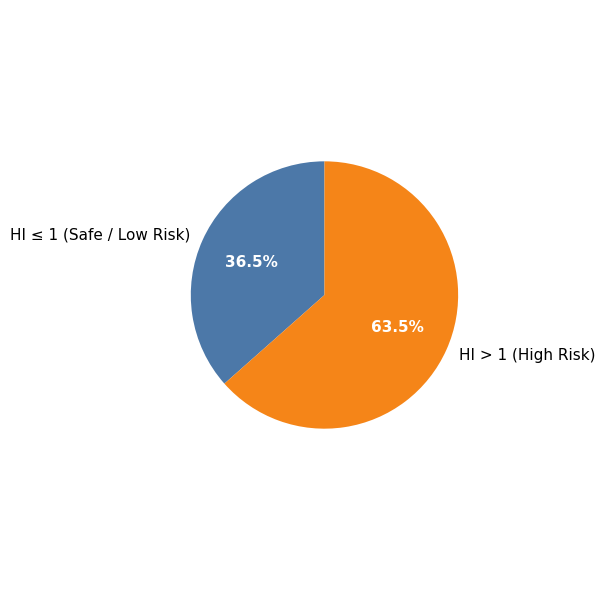

In [ ]:
import matplotlib.pyplot as plt

# =========================
# 1. Count samples
# =========================
hi_leq_1 = (df["HI"] <= 1).sum()
hi_gt_1  = (df["HI"] > 1).sum()

sizes = [hi_leq_1, hi_gt_1]
labels = ["HI ≤ 1 (Safe / Low Risk)", "HI > 1 (High Risk)"]

# Colors (clean publication style)
colors = ["#4C78A8", "#F58518"]

# =========================
# 2. Pie Chart
# =========================
plt.figure(figsize=(6, 6))

wedges, texts, autotexts = plt.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct="%1.1f%%",   # shows percentage on chart
    startangle=90,
    textprops={"fontsize": 11}
)

# Make percentage text bold
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_fontweight("bold")
    autotext.set_color("white")

# Title


plt.axis("equal")  # keeps pie circle perfectly round
plt.tight_layout()
plt.show()

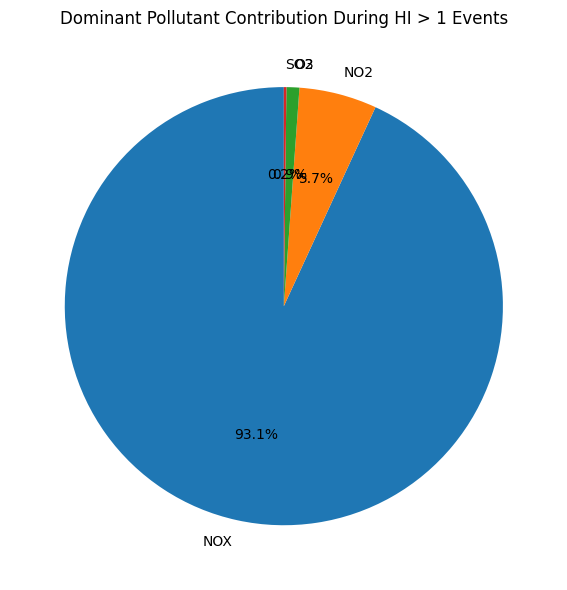

In [ ]:
import matplotlib.pyplot as plt

# Dominant pollutant counts
driver_counts = {
    'NOX': 47318,
    'NO2': 2913,
    'O3': 482,
    'SO2': 96
}

plt.figure(figsize=(7,6))

plt.pie(
    driver_counts.values(),
    labels=driver_counts.keys(),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Dominant Pollutant Contribution During HI > 1 Events')

plt.tight_layout()
plt.show()

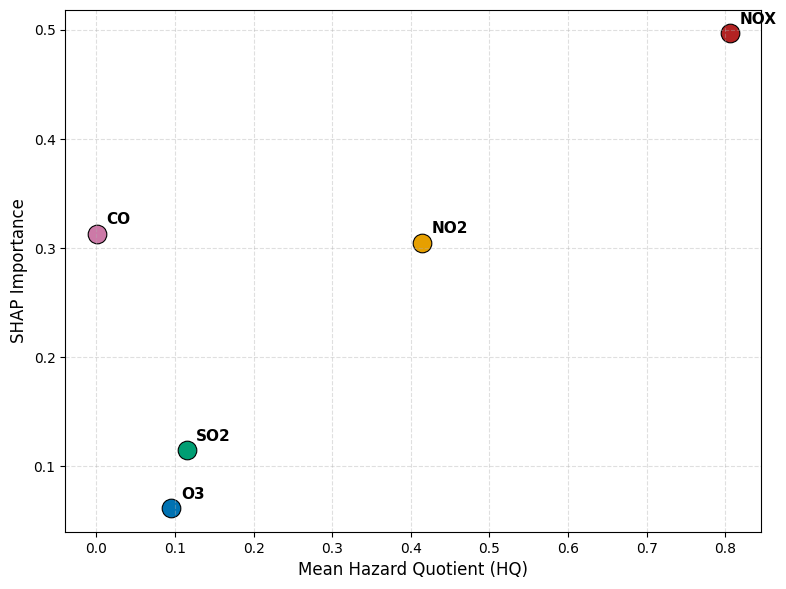

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

compare = pd.DataFrame({
    'Pollutant':['NOX','NO2','SO2','O3','CO'],
    'HQ':[0.805759,0.414440,0.114680,0.095108,0.000620],
    'SHAP':[0.4965,0.3046,0.1143,0.0616,0.3130]
})

colors = {
    'NOX':'#B22222',   # Firebrick Red
    'NO2':'#E69F00',   # Orange
    'SO2':'#009E73',   # Green
    'O3':'#0072B2',    # Blue
    'CO':'#CC79A7'     # Purple
}

plt.figure(figsize=(8,6))

for _, row in compare.iterrows():
    plt.scatter(
        row['HQ'],
        row['SHAP'],
        s=180,
        color=colors[row['Pollutant']],
        edgecolor='black',
        linewidth=0.8
    )

    plt.annotate(
        row['Pollutant'],
        (row['HQ'], row['SHAP']),
        xytext=(7,7),
        textcoords='offset points',
        fontsize=11,
        fontweight='bold'
    )

plt.xlabel('Mean Hazard Quotient (HQ)', fontsize=12)
plt.ylabel('SHAP Importance', fontsize=12)


plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

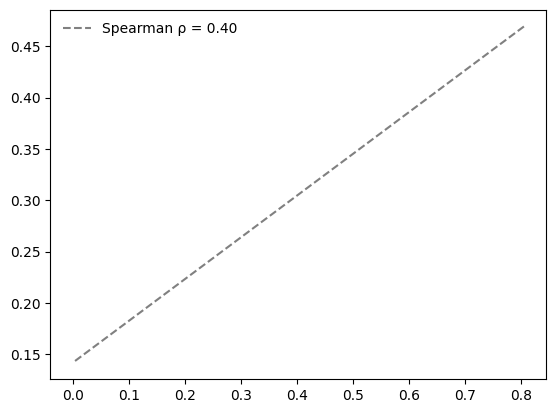

In [ ]:
from scipy.stats import spearmanr
import numpy as np

rho, p = spearmanr(compare['HQ'], compare['SHAP'])

z = np.polyfit(compare['HQ'], compare['SHAP'], 1)
pfit = np.poly1d(z)

plt.plot(
    compare['HQ'],
    pfit(compare['HQ']),
    '--',
    color='gray',
    linewidth=1.5,
    label=f'Spearman ρ = {rho:.2f}'
)

plt.legend(frameon=False)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80064 entries, 0 to 80063
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          80064 non-null  object 
 1   Time          71592 non-null  object 
 2   SO2           80064 non-null  float64
 3   NO            80064 non-null  float64
 4   NO2           80064 non-null  float64
 5   NOX           80064 non-null  float64
 6   CO            80064 non-null  float64
 7   CO 8hr        80064 non-null  float64
 8   O3            80064 non-null  float64
 9   O3 8hr        80064 non-null  float64
 10  PM2.5         80064 non-null  float64
 11  PM10          80064 non-null  float64
 12  Wind Speed    80064 non-null  float64
 13  Wind Dir      80064 non-null  float64
 14  Temperature   80064 non-null  float64
 15  RH            80064 non-null  float64
 16  Solar Rad     80064 non-null  float64
 17  BP            80064 non-null  float64
 18  Rain          80064 non-nu

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau

# ================================
# 1) Input Data (from your results)
# ================================
# Mean HQ values (already computed earlier)
hq_s = mean_HQs.copy()

# SHAP importance (High PM class)
shap_importance_highPM = {
    "SO2": 0.1143,
    "NO2": 0.3046,
    "NOX": 0.4965,
    "CO": 0.3130,
    "O3": 0.0616
}
shap_s = pd.Series(shap_importance_highPM, name="SHAP")

# Align both series
compare = pd.concat([hq_s.rename("HQ"), shap_s], axis=1).fillna(0.0)

# ================================
# 2) Normalize (Min-Max Scaling)
# ================================
hq_norm = (compare["HQ"] - compare["HQ"].min()) / (compare["HQ"].max() - compare["HQ"].min())
shap_norm = (compare["SHAP"] - compare["SHAP"].min()) / (compare["SHAP"].max() - compare["SHAP"].min())

compare["HQ_norm"] = hq_norm
compare["SHAP_norm"] = shap_norm

# ================================
# 3) Policy Score (Base Case: Equal Weight)
# ================================
compare["Policy_Score_0.5"] = 0.5 * hq_norm + 0.5 * shap_norm

print("\n🏆 Policy Priority Ranking (Equal Weight):")
print(compare.sort_values("Policy_Score_0.5", ascending=False).round(4))

# ================================
# 4) Sensitivity Analysis (IMPORTANT 🔥)
# ================================
weights = [0.3, 0.5, 0.7]  # Different importance to HQ

ranking_results = {}

print("\n🔍 Sensitivity Analysis (Different Weights):")

for w in weights:
    score = w * hq_norm + (1 - w) * shap_norm
    rank = score.sort_values(ascending=False)

    ranking_results[w] = rank.index.tolist()

    print(f"\nWeight HQ={w}, SHAP={1-w}")
    print(rank.round(4))

# ================================
# 5) Stability Check (Very Important)
# ================================
print("\n📊 Ranking Stability Check:")

base_ranking = ranking_results[0.5]

for w in weights:
    corr, _ = spearmanr(
        pd.Series(base_ranking).map({k:i for i,k in enumerate(base_ranking)}),
        pd.Series(ranking_results[w]).map({k:i for i,k in enumerate(ranking_results[w])})
    )
    print(f"Spearman correlation with base (0.5) for weight {w}: {corr:.3f}")

# ================================
# 6) HQ vs SHAP Correlation (Support Analysis)
# ================================
sp = spearmanr(compare["HQ"], compare["SHAP"])
kt = kendalltau(compare["HQ"], compare["SHAP"])

print("\n📈 HQ vs SHAP Correlation:")
print(f"Spearman ρ: {sp.correlation:.3f} (p={sp.pvalue:.3g})")
print(f"Kendall τ: {kt.correlation:.3f} (p={kt.pvalue:.3g})")

# ================================
# 7) Visualization
# ================================
# Bar plot of policy score
colors = ['#D55E00',  # NOX  — red/orange: highest priority
          '#E69F00',  # NO2  — amber: second
          '#56B4E9',  # CO   — blue: third
          '#888780',  # SO2  — grey: fourth
          '#B4B2A9']  # O3   — light grey: lowest
compare["Policy_Score_0.5"].sort_values(ascending=False).plot(kind="bar")
plt.title("Pollutant Policy Priority (Equal Weight)")
plt.ylabel("Priority Score")
plt.xlabel("Pollutant")
plt.tight_layout()
plt.savefig("policy_priority_bar.png", dpi=300)
plt.clf()

# Combined comparison plot
compare[["HQ_norm", "SHAP_norm", "Policy_Score_0.5"]].plot(kind="bar")

plt.ylabel("Normalized Value")
plt.tight_layout()
plt.savefig("hq_shap_policy_comparison.png", dpi=300)
plt.clf()

# ================================
# 8) Final Top Pollutant
# ================================
top_pollutant = compare["Policy_Score_0.5"].idxmax()

print(f"\n🏁 Final Recommendation: Control '{top_pollutant}' first.")


🏆 Policy Priority Ranking (Equal Weight):
         HQ    SHAP  HQ_norm  SHAP_norm  Policy_Score_0.5
NOX  0.8058  0.4965   1.0000     1.0000            1.0000
NO2  0.4144  0.3046   0.5140     0.5587            0.5364
CO   0.0006  0.3130   0.0000     0.5781            0.2890
SO2  0.1147  0.1143   0.1417     0.1212            0.1314
O3   0.0951  0.0616   0.1174     0.0000            0.0587

🔍 Sensitivity Analysis (Different Weights):

Weight HQ=0.3, SHAP=0.7
NOX    1.0000
NO2    0.5453
CO     0.4046
SO2    0.1273
O3     0.0352
dtype: float64

Weight HQ=0.5, SHAP=0.5
NOX    1.0000
NO2    0.5364
CO     0.2890
SO2    0.1314
O3     0.0587
dtype: float64

Weight HQ=0.7, SHAP=0.30000000000000004
NOX    1.0000
NO2    0.5274
CO     0.1734
SO2    0.1355
O3     0.0821
dtype: float64

📊 Ranking Stability Check:
Spearman correlation with base (0.5) for weight 0.3: 1.000
Spearman correlation with base (0.5) for weight 0.5: 1.000
Spearman correlation with base (0.5) for weight 0.7: 1.000

📈 HQ vs SHAP

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

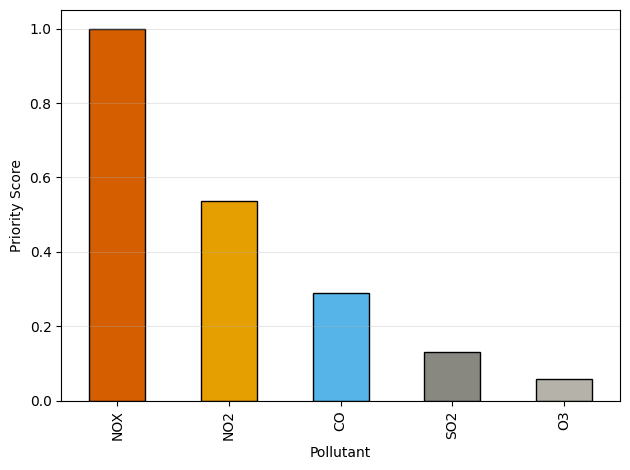

In [ ]:
priority = compare["Policy_Score_0.5"].sort_values(ascending=False)

color_map = {
    'NOX':'#D55E00',
    'NO2':'#E69F00',
    'CO':'#56B4E9',
    'SO2':'#888780',
    'O3':'#B4B2A9'
}

bar_colors = [color_map[p] for p in priority.index]

priority.plot(
    kind='bar',
    color=bar_colors,
    edgecolor='black'
)


plt.ylabel("Priority Score")
plt.xlabel("Pollutant")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

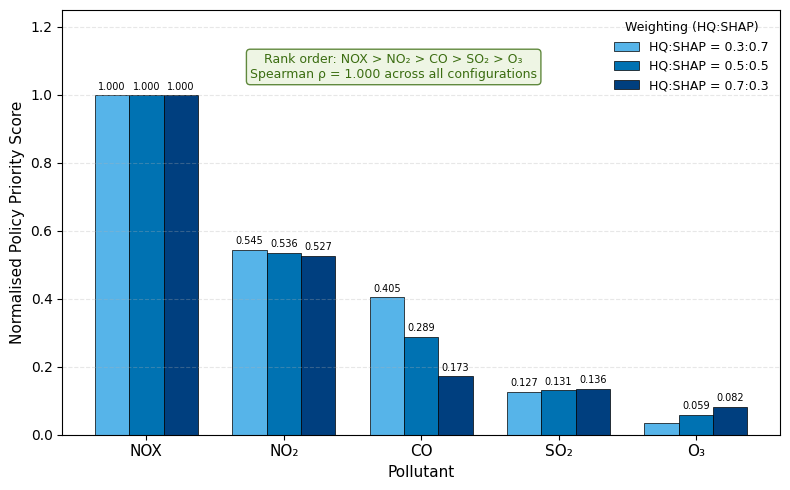

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

pollutants = ['NOX', 'NO\u2082', 'CO', 'SO\u2082', 'O\u2083']

# Three weight scenarios
scores_03 = [1.000, 0.545, 0.405, 0.127, 0.035]
scores_05 = [1.000, 0.536, 0.289, 0.131, 0.059]
scores_07 = [1.000, 0.527, 0.173, 0.136, 0.082]

x = np.arange(len(pollutants))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

b1 = ax.bar(x - width, scores_03, width,
            label='HQ:SHAP = 0.3:0.7',
            color='#56B4E9', edgecolor='black',
            linewidth=0.5)
b2 = ax.bar(x, scores_05, width,
            label='HQ:SHAP = 0.5:0.5',
            color='#0072B2', edgecolor='black',
            linewidth=0.5)
b3 = ax.bar(x + width, scores_07, width,
            label='HQ:SHAP = 0.7:0.3',
            color='#003f7f', edgecolor='black',
            linewidth=0.5)

# Add value labels
for bars in [b1, b2, b3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0.05:
            ax.text(bar.get_x() + bar.get_width()/2,
                    height + 0.01,
                    f'{height:.3f}',
                    ha='center', va='bottom',
                    fontsize=7, fontweight='500')

ax.set_xticks(x)
ax.set_xticklabels(pollutants, fontsize=11)
ax.set_xlabel(r'Pollutant', fontsize=11)
ax.set_ylabel('Normalised Policy Priority Score', fontsize=11)

ax.legend(frameon=False, fontsize=9,
          title='Weighting (HQ:SHAP)',
          title_fontsize=9)
ax.set_ylim(0, 1.25)

# Add stability annotation
ax.text(1.8, 1.05,  # shift right and up
        'Rank order: NOX > NO\u2082 > CO > SO\u2082 > O\u2083\n'
        'Spearman \u03c1 = 1.000 across all configurations',
        fontsize=9, color='#3B6D11',
        ha='center',
        bbox=dict(boxstyle='round,pad=0.3',
                 facecolor='#EAF3DE',
                 edgecolor='#3B6D11',
                 alpha=0.8))

ax.grid(True, axis='y', linestyle='--', alpha=0.3)
fig.tight_layout()
fig.savefig('fig_policy_priority.tiff',
            dpi=300, bbox_inches='tight')
plt.show()


📊 Correlation: PM2.5 vs Health Index (HI)
Pearson r: 0.3697 (p=0)
Spearman ρ: 0.4677 (p=0)

📈 Health Risk by PM2.5 Level:
               mean      max  count
PM2.5_Level                        
High PM      1.6402  16.3546  54652
Low PM       0.7908  13.4595   7896
Medium PM    1.0650  14.8797  17516

🌫️ Pollutant Levels across PM Categories:
                SO2      NO2      NOX      CO      O3
PM2.5_Level                                          
High PM      4.7669  11.7692  28.6505  2.6347  9.4608
Low PM       4.1042   5.8590  10.9327  1.9351  8.8931
Medium PM    4.2441   7.9966  16.1703  2.2398  9.9455

🏁 Dominant Pollutants in High PM Conditions:
NOX    28.6505
NO2    11.7692
O3      9.4608
SO2     4.7669
CO      2.6347
dtype: float64


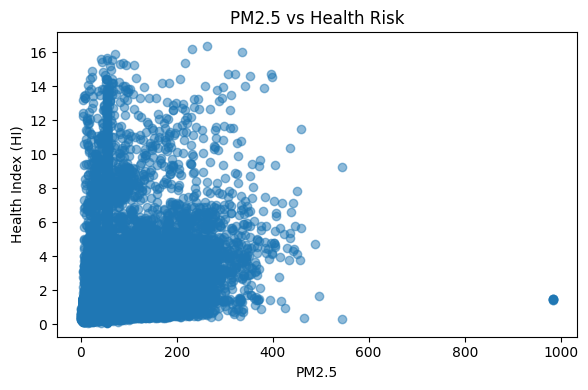

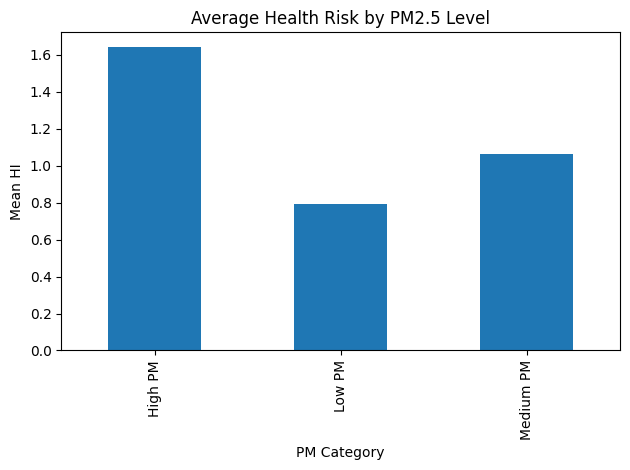

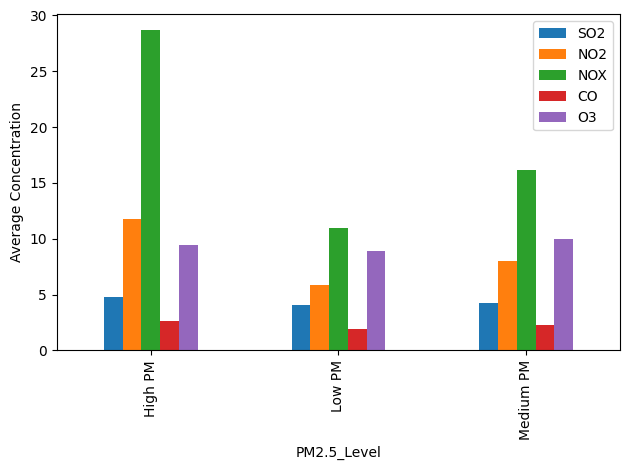


🧠 Interpretation Summary:
✔ Moderate relationship between PM2.5 and health risk.
✔ 'NOX' is the main driver during high PM events.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

# ================================
# 1) Copy dataset
# ================================
df_pm = df.copy()

# ================================
# 2) Correlation: PM2.5 vs Health Risk (HI)
# ================================
print("\n📊 Correlation: PM2.5 vs Health Index (HI)")

pearson_corr, p1 = pearsonr(df_pm["PM2.5"], df_pm["HI"])
spearman_corr, p2 = spearmanr(df_pm["PM2.5"], df_pm["HI"])

print(f"Pearson r: {pearson_corr:.4f} (p={p1:.4g})")
print(f"Spearman ρ: {spearman_corr:.4f} (p={p2:.4g})")

# ================================
# 3) Group by PM Level
# ================================
group_stats = df_pm.groupby("PM2.5_Level")["HI"].agg(["mean", "max", "count"])

print("\n📈 Health Risk by PM2.5 Level:")
print(group_stats.round(4))

# ================================
# 4) Average pollutant concentration per PM level
# ================================
pollutants = ["SO2", "NO2", "NOX", "CO", "O3"]

pollutant_analysis = df_pm.groupby("PM2.5_Level")[pollutants].mean()

print("\n🌫️ Pollutant Levels across PM Categories:")
print(pollutant_analysis.round(4))

# ================================
# 5) Identify dominant pollutant in HIGH PM cases
# ================================
high_pm = df_pm[df_pm["PM2.5_Level"] == "High PM"]

if not high_pm.empty:
    dominant = high_pm[pollutants].mean().sort_values(ascending=False)

    print("\n🏁 Dominant Pollutants in High PM Conditions:")
    print(dominant.round(4))

# ================================
# 6) Visualization
# ================================

# --- Scatter plot: PM2.5 vs HI ---
plt.figure(figsize=(6,4))
plt.scatter(df_pm["PM2.5"], df_pm["HI"], alpha=0.5)
plt.xlabel("PM2.5")
plt.ylabel("Health Index (HI)")
plt.title("PM2.5 vs Health Risk")
plt.tight_layout()
plt.savefig("pm_vs_hi_scatter.png", dpi=300)
plt.show()

# --- Bar plot: Average HI by PM Level ---
group_stats["mean"].plot(kind="bar")
plt.title("Average Health Risk by PM2.5 Level")
plt.ylabel("Mean HI")
plt.xlabel("PM Category")
plt.tight_layout()
plt.savefig("hi_by_pm_level.png", dpi=300)
plt.show()

# --- Pollutant comparison ---
pollutant_analysis.plot(kind="bar")

plt.ylabel("Average Concentration")
plt.tight_layout()
plt.savefig("pollutants_by_pm_level.png", dpi=300)
plt.show()

# ================================
# 7) Simple Interpretation Output
# ================================
print("\n🧠 Interpretation Summary:")

if spearman_corr > 0.5:
    print("✔ Strong positive relationship between PM2.5 and health risk.")
elif spearman_corr > 0.2:
    print("✔ Moderate relationship between PM2.5 and health risk.")
else:
    print("✔ Weak relationship between PM2.5 and health risk.")

if not high_pm.empty:
    top_pollutant = dominant.idxmax()
    print(f"✔ '{top_pollutant}' is the main driver during high PM events.")

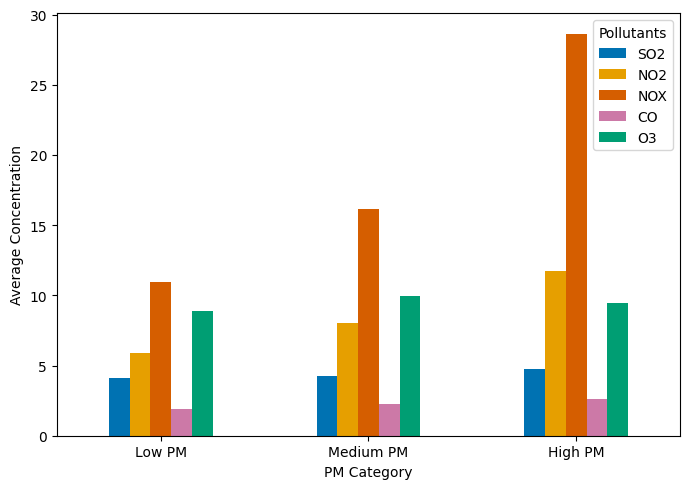

In [ ]:
# --- Pollutant comparison (POLISHED) ---

# Define correct PM order
pm_order = ["Low PM", "Medium PM", "High PM"]

# Reindex dataframe to enforce order
pollutant_plot = pollutant_analysis.reindex(pm_order)

# Define custom colors for pollutants
colors = {
    "SO2": "#0072B2",
    "NO2": "#E69F00",
    "NOX": "#D55E00",
    "CO": "#CC79A7",
    "O3": "#009E73"
}

# Plot
ax = pollutant_plot.plot(kind="bar", figsize=(7,5), color=[colors[col] for col in pollutant_plot.columns])


plt.ylabel("Average Concentration")
plt.xlabel("PM Category")

plt.xticks(rotation=0)
plt.legend(title="Pollutants")

plt.tight_layout()
plt.savefig("pollutants_by_pm_level.png", dpi=300)
plt.show()

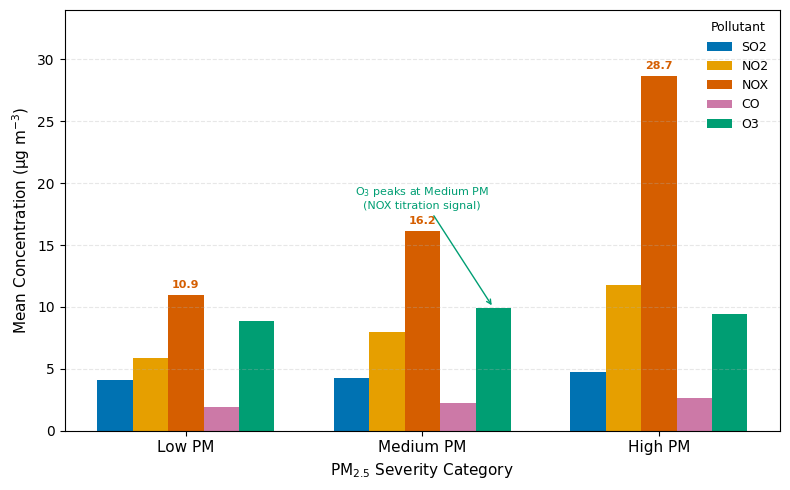

In [ ]:
# --- POLLUTANT COMPARISON (ADVANCED FIGURE) ---

pm_order = ["Low PM", "Medium PM", "High PM"]
categories = pm_order

pollutant_plot = pollutant_analysis.reindex(pm_order)

pollutants = ["SO2", "NO2", "NOX", "CO", "O3"]

colors = {
    'SO2': '#0072B2',   # blue
    'NO2': '#E69F00',   # amber/yellow
    'NOX': '#D55E00',   # red-orange — more distinct from NO2
    'CO':  '#CC79A7',   # pink
    'O3':  '#009E73'    # teal
}

x = np.arange(len(categories))
width = 0.15
offsets = np.linspace(-2*width, 2*width, len(pollutants))

fig, ax = plt.subplots(figsize=(8,5))

for i, poll in enumerate(pollutants):
    bars = ax.bar(x + offsets[i],
                  pollutant_plot[poll],
                  width=width,
                  label=poll,
                  color=colors[poll])

    # Label NOX bars only
    if poll == 'NOX':
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2,
                    height + 0.4,
                    f'{height:.1f}',
                    ha='center', va='bottom',
                    fontsize=8, fontweight='600',
                    color=colors['NOX'])

# O3 annotation
# Fix annotation coordinates
o3_val = pollutant_plot.loc["Medium PM", "O3"]

ax.annotate(
    'O$_3$ peaks at Medium PM\n(NOX titration signal)',
    xy=(1 + offsets[4], o3_val),
    xytext=(1, o3_val + 8),   # 👈 lifted above the bar automatically
    ha='center',
    fontsize=8,
    color=colors['O3'],
    arrowprops=dict(arrowstyle='->', color=colors['O3'], lw=1)
)

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11)
ax.set_xlabel(r'PM$_{2.5}$ Severity Category', fontsize=11)
ax.set_ylabel(r'Mean Concentration (µg m$^{-3}$)', fontsize=11)



ax.legend(title='Pollutant', frameon=False, fontsize=9, title_fontsize=9)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.set_ylim(0, 34)

fig.tight_layout()
fig.savefig('fig_pollutant_by_pm_level.tiff', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
results = {
    'pearson_r': pearson_corr,
    'spearman_rho': spearman_corr,
    'dominant_high_pm': top_pollutant,
    'mean_HI_high_pm': group_stats.loc["High PM", "mean"]
}

pd.DataFrame([results]).to_csv('statistical_validation.csv', index=False)

<Figure size 600x400 with 0 Axes>

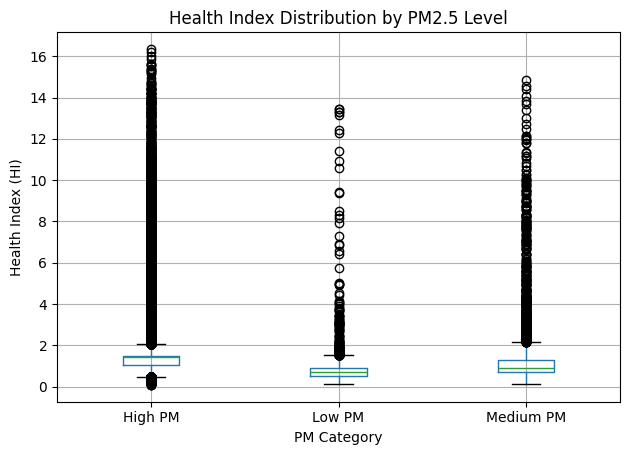

In [ ]:
# --- Boxplot: HI distribution across PM Levels ---
plt.figure(figsize=(6,4))

df_pm.boxplot(column="HI", by="PM2.5_Level")

plt.title("Health Index Distribution by PM2.5 Level")
plt.suptitle("")  # removes default pandas title
plt.xlabel("PM Category")
plt.ylabel("Health Index (HI)")

plt.tight_layout()
plt.savefig("hi_boxplot_by_pm_level.png", dpi=300)
plt.show()

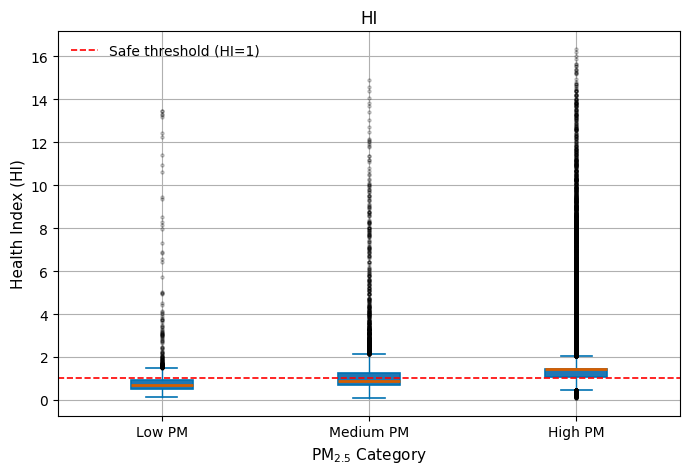

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

# Order categories logically
order = ['Low PM', 'Medium PM', 'High PM']
df_plot = df.copy()
df_plot['PM2.5_Level'] = pd.Categorical(
    df_plot['PM2.5_Level'], categories=order, ordered=True
)

# Cleaner boxplot
bp = df_plot.boxplot(
    column='HI', by='PM2.5_Level', ax=ax,
    boxprops=dict(color='#0072B2', linewidth=1.2),
    medianprops=dict(color='#D55E00', linewidth=2),
    whiskerprops=dict(color='#0072B2', linewidth=1),
    capprops=dict(color='#0072B2', linewidth=1.2),
    flierprops=dict(marker='o', markersize=2,
                   alpha=0.3, color='#888780'),
    patch_artist=True
)

ax.axhline(y=1.0, color='red', linewidth=1.2,
           linestyle='--', label='Safe threshold (HI=1)')

ax.set_xlabel('PM$_{2.5}$ Category', fontsize=11)
ax.set_ylabel('Health Index (HI)', fontsize=11)
ax.legend(frameon=False)
plt.suptitle('')  # remove auto-generated title
fig.tight_layout()
fig.savefig('fig_hi_boxplot.tiff', dpi=300)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80064 entries, 0 to 80063
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          80064 non-null  object 
 1   Time          71592 non-null  object 
 2   SO2           80064 non-null  float64
 3   NO            80064 non-null  float64
 4   NO2           80064 non-null  float64
 5   NOX           80064 non-null  float64
 6   CO            80064 non-null  float64
 7   CO 8hr        80064 non-null  float64
 8   O3            80064 non-null  float64
 9   O3 8hr        80064 non-null  float64
 10  PM2.5         80064 non-null  float64
 11  PM10          80064 non-null  float64
 12  Wind Speed    80064 non-null  float64
 13  Wind Dir      80064 non-null  float64
 14  Temperature   80064 non-null  float64
 15  RH            80064 non-null  float64
 16  Solar Rad     80064 non-null  float64
 17  BP            80064 non-null  float64
 18  Rain          80064 non-nu


🔥 SHAP-BASED CAUSAL INFLUENCE RANKING
       Mean_SHAP  Direction_Consistency  Perturbation_Effect  Stability  \
NO2     0.143896               0.549491             0.181102   0.985636   
NOX     0.506746               0.158808             0.171187   0.985636   
O3      0.038392               0.451820             0.050392   0.985636   
SO2     0.031217               0.226441             0.107568   0.985636   
PM2.5   0.005598               0.595766            -0.000543   0.985636   
CO      0.005674               0.199900            -0.006263   0.985636   

       Causal_Plausibility_Score  
NO2                     0.014114  
NOX                     0.013578  
O3                      0.000862  
SO2                     0.000749  
PM2.5                  -0.000002  
CO                     -0.000007  


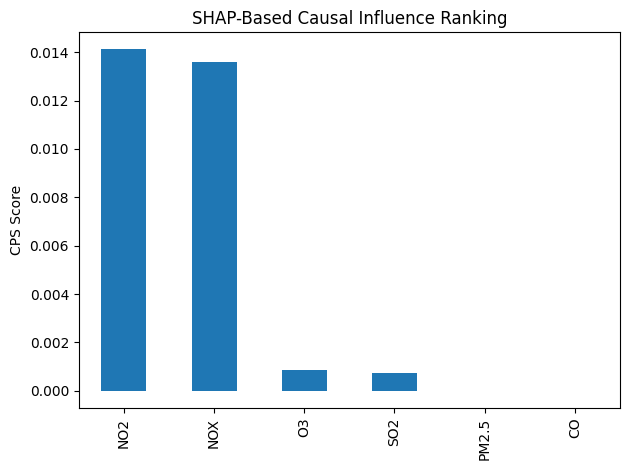


🏁 FINAL CAUSAL DRIVER:
👉 NO2 is the strongest causal contributor to HI (model-based inference)


In [ ]:
# =========================================
# 0) IMPORT LIBRARIES
# =========================================
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

import shap

# =========================================
# 1) LOAD DATA
# =========================================
df_model = df.copy()

features = ["PM2.5", "NO2", "NOX", "SO2", "CO", "O3"]
target = "HI"

X = df_model[features]
y = df_model[target]

# =========================================
# 2) TRAIN-TEST SPLIT
# =========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# =========================================
# 3) TRAIN MODEL (XGBOOST)
# =========================================
model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)

# =========================================
# 4) SHAP EXPLANATION
# =========================================
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Convert to DataFrame
shap_df = pd.DataFrame(shap_values, columns=features)

# =========================================
# 5) GLOBAL SHAP IMPORTANCE
# =========================================
mean_abs_shap = np.abs(shap_df).mean()

# Direction consistency (how often SHAP is positive)
direction_consistency = (shap_df > 0).mean()

# =========================================
# 6) PERTURBATION-BASED SENSITIVITY (CAUSAL TEST)
# =========================================
def perturb_effect(model, X, feature, delta=5):
    X_temp = X.copy()
    X_temp[feature] = X_temp[feature] + delta
    return model.predict(X_temp).mean() - model.predict(X).mean()

perturbation_effect = {}
for f in features:
    perturbation_effect[f] = perturb_effect(model, X_test, f, delta=5)

perturbation_effect = pd.Series(perturbation_effect)

# =========================================
# 7) STABILITY CHECK (BOOTSTRAP SHAP)
# =========================================
n_boot = 5
bootstrap_shap = []

for i in range(n_boot):
    sample = X_test.sample(frac=0.8, replace=True, random_state=i)
    shap_vals = explainer.shap_values(sample)
    bootstrap_shap.append(np.abs(shap_vals).mean(axis=0))

bootstrap_shap = pd.DataFrame(bootstrap_shap, columns=features)
stability = 1 - bootstrap_shap.std() / (bootstrap_shap.mean() + 1e-8)
stability = stability.fillna(0)

# =========================================
# 8) CAUSAL PLAUSIBILITY SCORE (CPS)
# =========================================
cps = (
    mean_abs_shap *
    direction_consistency *
    stability.mean() *
    perturbation_effect
)

cps = cps.sort_values(ascending=False)

# =========================================
# 9) RESULTS TABLE
# =========================================
results = pd.DataFrame({
    "Mean_SHAP": mean_abs_shap,
    "Direction_Consistency": direction_consistency,
    "Perturbation_Effect": perturbation_effect,
    "Stability": stability.mean(),
    "Causal_Plausibility_Score": cps
}).sort_values("Causal_Plausibility_Score", ascending=False)

print("\n🔥 SHAP-BASED CAUSAL INFLUENCE RANKING")
print(results)

# =========================================
# 10) VISUALIZATION (OPTIONAL BUT RECOMMENDED)
# =========================================
import matplotlib.pyplot as plt

results["Causal_Plausibility_Score"].plot(kind="bar")
plt.title("SHAP-Based Causal Influence Ranking")
plt.ylabel("CPS Score")
plt.tight_layout()
plt.show()

# =========================================
# 11) FINAL CONCLUSION
# =========================================
top_driver = results.index[0]

print("\n🏁 FINAL CAUSAL DRIVER:")
print(f"👉 {top_driver} is the strongest causal contributor to HI (model-based inference)")


Classification Report (Decision Tree):
              precision    recall  f1-score   support

     High PM       0.91      0.91      0.91     10931
      Low PM       0.58      0.57      0.58      1579
   Medium PM       0.69      0.69      0.69      3503

    accuracy                           0.83     16013
   macro avg       0.73      0.73      0.73     16013
weighted avg       0.83      0.83      0.83     16013

Accuracy: 0.8315


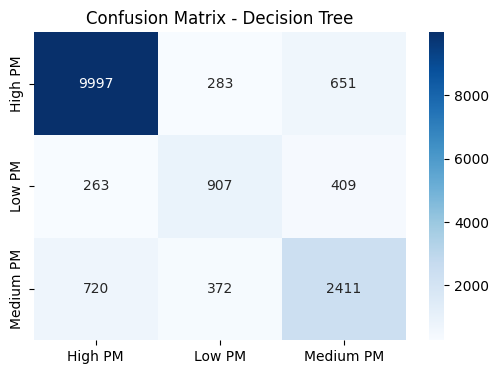


Classification Report (Random Forest):
              precision    recall  f1-score   support

     High PM       0.96      0.90      0.93     10931
      Low PM       0.60      0.75      0.67      1579
   Medium PM       0.73      0.81      0.77      3503

    accuracy                           0.86     16013
   macro avg       0.77      0.82      0.79     16013
weighted avg       0.88      0.86      0.87     16013

Accuracy: 0.8625


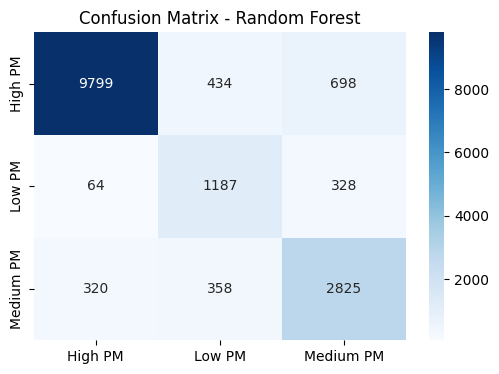


Classification Report (XGBoost):
              precision    recall  f1-score   support

     High PM       0.94      0.94      0.94     10931
      Low PM       0.67      0.66      0.67      1579
   Medium PM       0.77      0.78      0.78      3503

    accuracy                           0.88     16013
   macro avg       0.80      0.80      0.80     16013
weighted avg       0.88      0.88      0.88     16013

Accuracy: 0.8779


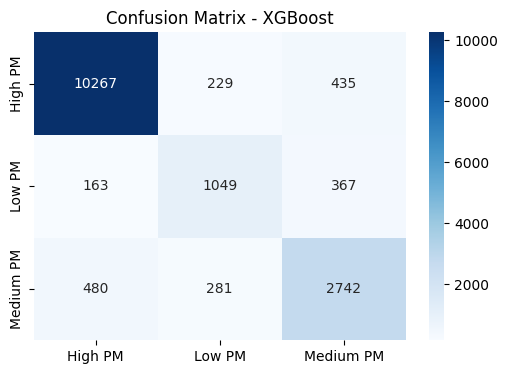

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.026292 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4233
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 17
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Classification Report (LightGBM):
              precision    recall  f1-score   support

     High PM       0.97      0.88      0.92     10931
      Low PM       0.56      0.81      0.66      1579
   Medium PM       0.72      0.79      0.76      3503

    accuracy                           0.85     16013
   macro avg       0.75      0.83      0.78     16013
weighted avg       0.88      0.85      0.86     16013

Accuracy: 0.8530


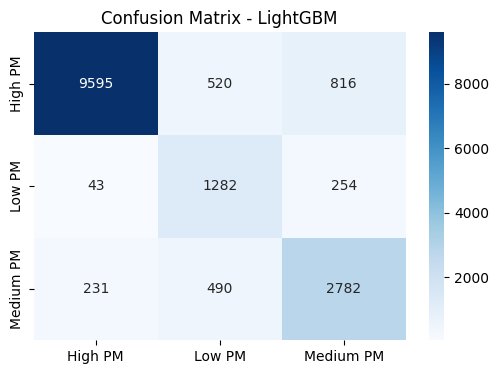


Regression Performance (Decision Tree - HI Prediction):
R² Score: 0.9974
MSE: 0.0045


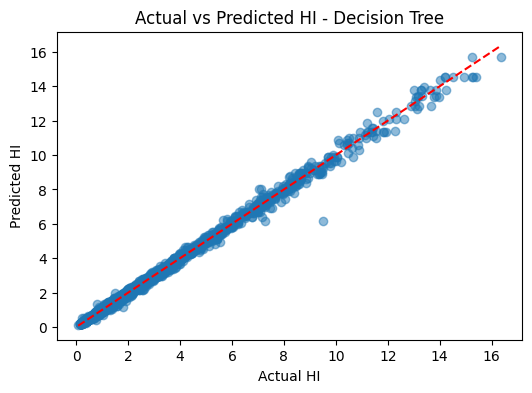


Regression Performance (Random Forest - HI Prediction):
R² Score: 0.9988
MSE: 0.0021


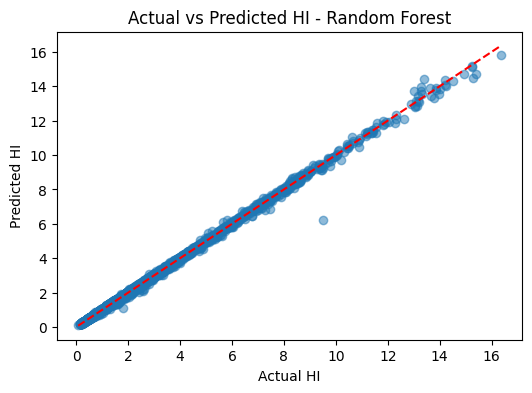


Regression Performance (XGBoost - HI Prediction):
R² Score: 0.9950
MSE: 0.0086


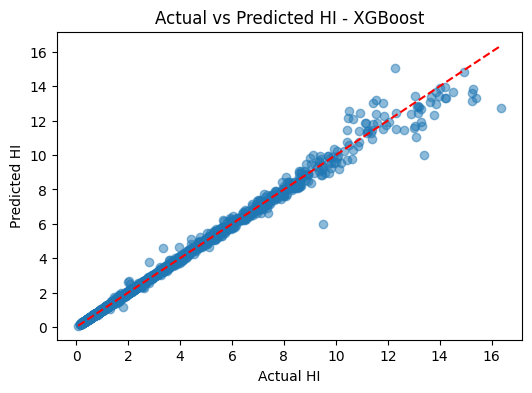

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.012577 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4230
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 17
[LightGBM] [Info] Start training from score 1.427739


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Regression Performance (LightGBM - HI Prediction):
R² Score: 0.9969
MSE: 0.0053


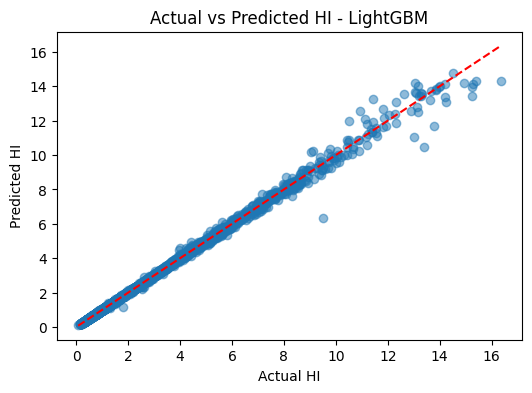

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004879 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4233
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 17
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612


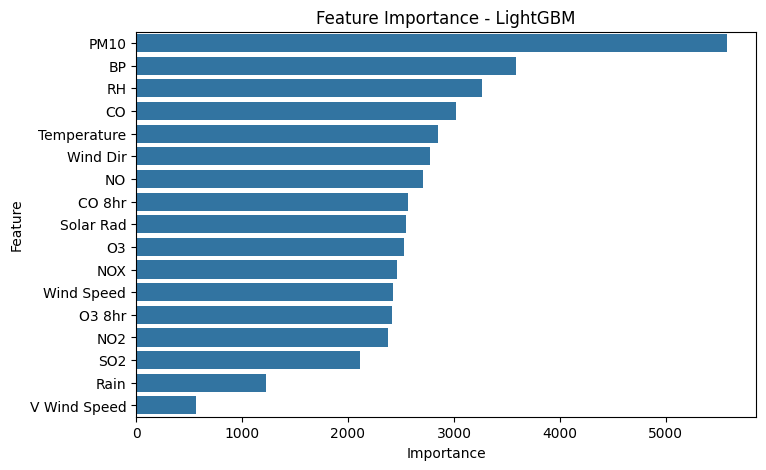

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    mean_squared_error, r2_score
)
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Models
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor

# -------------------------
# Drop datetime columns
# -------------------------
df_model = df.drop(["Date", "Time"], axis=1)

# -------------------------
# Encode target
# -------------------------
le = LabelEncoder()
df_model["PM2.5_Level"] = le.fit_transform(df_model["PM2.5_Level"])

# -------------------------
# Select features and target (modified)
# -------------------------
X = df_model.drop([
    'PM2.5', 'PM2.5_Level', 'HQ_SO2', 'HQ_NO2', 'HQ_NOX',
    'HQ_O3', 'HQ_CO', 'HI', 'CO_for_HQ'
], axis=1)

y = df_model['PM2.5_Level']   # classification target
y_reg = df_model['HI']        # regression target

# -------------------------
# Scaling
# -------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -------------------------
# Train/Test Split
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_scaled, y_reg, test_size=0.2, random_state=42
)

# -------------------------
# Helper function for classification
# -------------------------
def evaluate_classification(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\nClassification Report ({name}):")
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    return model

# -------------------------
# Helper function for regression
# -------------------------
def evaluate_regression(model, name):
    model.fit(X_train_reg, y_train_reg)
    y_pred = model.predict(X_test_reg)

    print(f"\nRegression Performance ({name} - HI Prediction):")
    print(f"R² Score: {r2_score(y_test_reg, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_test_reg, y_pred):.4f}")

    # Scatter plot (Predicted vs Actual)
    plt.figure(figsize=(6,4))
    plt.scatter(y_test_reg, y_pred, alpha=0.5)
    plt.xlabel("Actual HI")
    plt.ylabel("Predicted HI")
    plt.title(f"Actual vs Predicted HI - {name}")
    plt.plot([y_test_reg.min(), y_test_reg.max()],
             [y_test_reg.min(), y_test_reg.max()], 'r--')
    plt.show()

    return model

# -------------------------
# Classification Models
# -------------------------
dt = DecisionTreeClassifier(max_depth=15, min_samples_split=10, random_state=42)
evaluate_classification(dt, "Decision Tree")

rf = RandomForestClassifier(
    n_estimators=300, max_depth=20, min_samples_split=10,
    class_weight="balanced", random_state=42, n_jobs=-1
)
evaluate_classification(rf, "Random Forest")

xgb_clf = XGBClassifier(
    n_estimators=500, learning_rate=0.05, max_depth=10,
    subsample=0.8, colsample_bytree=0.8,
    objective="multi:softmax", num_class=len(le.classes_),
    random_state=42, n_jobs=-1
)
evaluate_classification(xgb_clf, "XGBoost")

lgb_clf = LGBMClassifier(
    n_estimators=500, learning_rate=0.05, max_depth=10,
    class_weight="balanced", random_state=42, n_jobs=-1
)
evaluate_classification(lgb_clf, "LightGBM")

# -------------------------
# Regression Models (HI Prediction)
# -------------------------
dt_reg = DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=42)
evaluate_regression(dt_reg, "Decision Tree")

rf_reg = RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1)
evaluate_regression(rf_reg, "Random Forest")

xgb_reg = XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=10,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1
)
evaluate_regression(xgb_reg, "XGBoost")

lgb_reg = LGBMRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=10,
    random_state=42, n_jobs=-1
)
evaluate_regression(lgb_reg, "LightGBM")

# -------------------------
# Feature Importance (LightGBM Classification)
# -------------------------
lgb_clf.fit(X_train, y_train)
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': lgb_clf.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Importance", y="Feature", data=feature_importances)
plt.title("Feature Importance - LightGBM")
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ==========================
# 1) Data Preparation
# ==========================
df_model = df.drop(["Date", "Time"], axis=1)

# Encode target
le = LabelEncoder()
df_model["PM2.5_Level"] = le.fit_transform(df_model["PM2.5_Level"])

# Features and target
X = df_model.drop([
    'PM2.5', 'PM2.5_Level',
    'HQ_SO2', 'HQ_NO2', 'HQ_NOX',
    'HQ_O3', 'HQ_CO', 'HI', 'CO_for_HQ'
], axis=1)

y = df_model['PM2.5_Level']

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# ==========================
# 2) Evaluation Function
# ==========================
def evaluate_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\n📊 Classification Report ({name}):")
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.savefig(f"cm_{name.lower().replace(' ', '_')}.png", dpi=300)
    plt.clf()

# ==========================
# 3) Cross Validation Function
# ==========================
def cross_validate_model(model, name, X, y):
    kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring='accuracy',
        n_jobs=-1
    )

    print(f"\n🔁 5-Fold Cross-Validation ({name}):")
    print(f"Scores: {scores}")
    print(f"Mean Accuracy: {scores.mean():.4f}")
    print(f"Std Dev: {scores.std():.4f}")

    return scores.mean(), scores.std()

# ==========================
# 4) Models
# ==========================
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)


dt = DecisionTreeClassifier(
    max_depth=15,
    min_samples_split=10,
    random_state=42
)

xgb_clf = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=len(le.classes_),
    random_state=42,
    n_jobs=-1
)

lgb_clf = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# ==========================
# 5) Train + Evaluate
# ==========================
evaluate_model(rf, "Random Forest")
evaluate_model(dt, "Decision Tree")
evaluate_model(xgb_clf, "XGBoost")
evaluate_model(lgb_clf, "LightGBM")

# ==========================
# 6) Cross Validation
# ==========================
rf_mean, rf_std = cross_validate_model(rf, "Random Forest", X_scaled, y)
dt_mean, dt_std = cross_validate_model(dt, "Decision Tree", X_scaled, y)
xgb_mean, xgb_std = cross_validate_model(xgb_clf, "XGBoost", X_scaled, y)
lgb_mean, lgb_std = cross_validate_model(lgb_clf, "LightGBM", X_scaled, y)

# ==========================
# 7) Comparison Table
# ==========================
results_df = pd.DataFrame({
    "Model": ["Random Forest","Decision tree", "XGBoost", "LightGBM"],
    "CV Mean Accuracy": [rf_mean,dt_mean, xgb_mean, lgb_mean],
    "CV Std Dev": [rf_std,dt_std, xgb_std, lgb_std]
})

print("\n🏆 Model Comparison (Cross-Validation):")
print(results_df.round(4))

# Optional: Save results
results_df.to_csv("model_comparison_cv.csv", index=False)


📊 Classification Report (Random Forest):
              precision    recall  f1-score   support

     High PM       0.96      0.90      0.93     10931
      Low PM       0.60      0.75      0.67      1579
   Medium PM       0.73      0.81      0.77      3503

    accuracy                           0.86     16013
   macro avg       0.77      0.82      0.79     16013
weighted avg       0.88      0.86      0.87     16013

Accuracy: 0.8625

📊 Classification Report (Decision Tree):
              precision    recall  f1-score   support

     High PM       0.91      0.91      0.91     10931
      Low PM       0.58      0.57      0.58      1579
   Medium PM       0.69      0.69      0.69      3503

    accuracy                           0.83     16013
   macro avg       0.73      0.73      0.73     16013
weighted avg       0.83      0.83      0.83     16013

Accuracy: 0.8315

📊 Classification Report (XGBoost):
              precision    recall  f1-score   support

     High PM       0.94      

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



📊 Classification Report (LightGBM):
              precision    recall  f1-score   support

     High PM       0.97      0.88      0.92     10931
      Low PM       0.56      0.81      0.66      1579
   Medium PM       0.72      0.79      0.76      3503

    accuracy                           0.85     16013
   macro avg       0.75      0.83      0.78     16013
weighted avg       0.88      0.85      0.86     16013

Accuracy: 0.8530

🔁 5-Fold Cross-Validation (Random Forest):
Scores: [0.86442266 0.85955161 0.86130019 0.85824018 0.86104172]
Mean Accuracy: 0.8609
Std Dev: 0.0021

🔁 5-Fold Cross-Validation (Decision Tree):
Scores: [0.83913071 0.83319803 0.83575845 0.83488416 0.83556083]
Mean Accuracy: 0.8357
Std Dev: 0.0019


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



🔁 5-Fold Cross-Validation (XGBoost):
Scores: [0.87866109 0.87472678 0.87616312 0.87691251 0.87634274]
Mean Accuracy: 0.8766
Std Dev: 0.0013

🔁 5-Fold Cross-Validation (LightGBM):
Scores: [0.85486792 0.84868544 0.85343159 0.84881034 0.84942543]
Mean Accuracy: 0.8510
Std Dev: 0.0026

🏆 Model Comparison (Cross-Validation):
           Model  CV Mean Accuracy  CV Std Dev
0  Random Forest            0.8609      0.0021
1  Decision tree            0.8357      0.0019
2        XGBoost            0.8766      0.0013
3       LightGBM            0.8510      0.0026


<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>


Classification Report (SVM):
              precision    recall  f1-score   support

     High PM       0.98      0.83      0.90     10931
      Low PM       0.49      0.82      0.62      1579
   Medium PM       0.62      0.74      0.67      3503

    accuracy                           0.81     16013
   macro avg       0.70      0.79      0.73     16013
weighted avg       0.85      0.81      0.82     16013

Accuracy: 0.8060


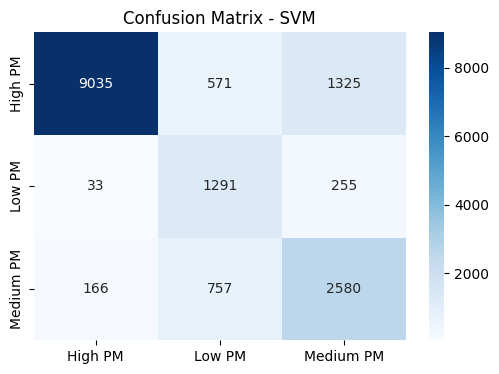

SVC(class_weight='balanced', random_state=42)

In [ ]:
# -------------------------
# SVM Classification Model
# -------------------------
from sklearn.svm import SVC, SVR
svm_clf = SVC(
    kernel='rbf',        # most commonly used
    C=1.0,               # regularization
    gamma='scale',       # auto handles feature scaling
    class_weight='balanced',
    random_state=42
)

evaluate_classification(svm_clf, "SVM")


Regression Performance (SVM - HI Prediction):
R² Score: 0.9716
MSE: 0.0493


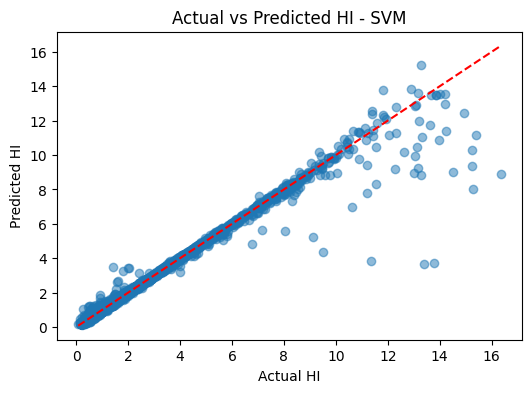

SVR()

In [ ]:
# -------------------------
# SVM Regression Model
# -------------------------
svm_reg = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,   # tolerance margin
    gamma='scale'
)

evaluate_regression(svm_reg, "SVM")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

# ==========================
# 1) Data Preparation
# ==========================
df_model = df.drop(["Date", "Time"], axis=1)

# Encode target
le = LabelEncoder()
df_model["PM2.5_Level"] = le.fit_transform(df_model["PM2.5_Level"])

# Features and target
X = df_model.drop([
    'PM2.5', 'PM2.5_Level',
    'HQ_SO2', 'HQ_NO2', 'HQ_NOX',
    'HQ_O3', 'HQ_CO', 'HI', 'CO_for_HQ'
], axis=1)

y = df_model['PM2.5_Level']

# ==========================
# 2) Train/Test Split
# ==========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==========================
# 3) SVM Pipeline (Scaling + Model)
# ==========================
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=10,
        gamma=0.1,
        class_weight='balanced',
        random_state=42
    ))
])

# ==========================
# 4) Evaluation Function
# ==========================
def evaluate_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\n📊 Classification Report ({name}):")
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.savefig(f"cm_{name.lower().replace(' ', '_')}.png", dpi=300)
    plt.clf()

# ==========================
# 5) Cross Validation Function
# ==========================
def cross_validate_model(model, name, X, y):
    kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring='accuracy',
        n_jobs=-1
    )

    print(f"\n🔁 5-Fold Cross-Validation ({name}):")
    print(f"Scores: {scores}")
    print(f"Mean Accuracy: {scores.mean():.4f}")
    print(f"Std Dev: {scores.std():.4f}")

    return scores.mean(), scores.std()

# ==========================
# 6) Train + Evaluate
# ==========================
evaluate_model(svm_pipeline, "SVM")

# ==========================
# 7) Cross Validation
# ==========================
svm_mean, svm_std = cross_validate_model(svm_pipeline, "SVM", X, y)

# ==========================
# 8) Comparison Table (Single Model)
# ==========================
results_df = pd.DataFrame({
    "Model": ["SVM"],
    "CV Mean Accuracy": [svm_mean],
    "CV Std Dev": [svm_std]
})

print("\n🏆 SVM Performance (Cross-Validation):")
print(results_df.round(4))

# Save results
results_df.to_csv("svm_cv_results.csv", index=False)


📊 Classification Report (SVM):
              precision    recall  f1-score   support

     High PM       0.97      0.86      0.91     10931
      Low PM       0.52      0.79      0.63      1579
   Medium PM       0.68      0.77      0.72      3503

    accuracy                           0.83     16013
   macro avg       0.72      0.81      0.75     16013
weighted avg       0.86      0.83      0.84     16013

Accuracy: 0.8301

🔁 5-Fold Cross-Validation (SVM):
Scores: [0.835696   0.82726535 0.82689065 0.82395554 0.83031476]
Mean Accuracy: 0.8288
Std Dev: 0.0040

🏆 SVM Performance (Cross-Validation):
  Model  CV Mean Accuracy  CV Std Dev
0   SVM            0.8288       0.004


<Figure size 600x400 with 0 Axes>

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.4 MB/s eta 0:00:00



Classification Report (CatBoost):
              precision    recall  f1-score   support

     High PM       0.93      0.92      0.93     10931
      Low PM       0.64      0.62      0.63      1579
   Medium PM       0.72      0.77      0.75      3503

    accuracy                           0.86     16013
   macro avg       0.76      0.77      0.77     16013
weighted avg       0.86      0.86      0.86     16013

Accuracy: 0.8575


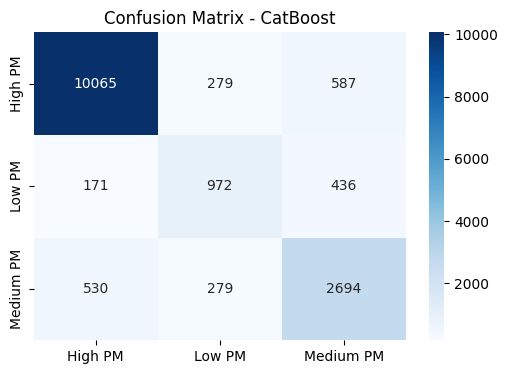


Regression Performance (CatBoost - HI Prediction):
R² Score: 0.9960
MSE: 0.0070


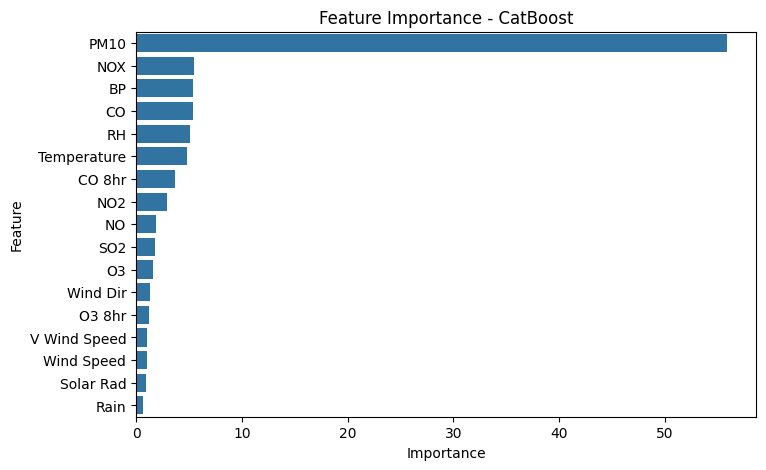

In [ ]:
from catboost import CatBoostClassifier, CatBoostRegressor

# -------------------------
# CatBoost Classification
# -------------------------
cat_clf = CatBoostClassifier(
     iterations=300,          # ↓ reduce
    learning_rate=0.03,      # ↓ slower learning
    depth=6,                 # ↓ less complex
    l2_leaf_reg=5,           # regularization ↑
    random_strength=1,       # randomness
    bagging_temperature=1,   # reduce overfit
    loss_function='MultiClass',
    random_seed=42,
    verbose=0
)
evaluate_classification(cat_clf, "CatBoost")

# -------------------------
# CatBoost Regression (HI Prediction)
# -------------------------
cat_reg = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=10,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)
cat_reg.fit(X_train_reg, y_train_reg)
y_pred_cat_reg = cat_reg.predict(X_test_reg)

print("\nRegression Performance (CatBoost - HI Prediction):")
print(f"R² Score: {r2_score(y_test_reg, y_pred_cat_reg):.4f}")
print(f"MSE: {mean_squared_error(y_test_reg, y_pred_cat_reg):.4f}")

# -------------------------
# Feature Importance (CatBoost)
# -------------------------
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': cat_clf.get_feature_importance()
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Importance", y="Feature", data=feature_importances)
plt.title("Feature Importance - CatBoost")
plt.show()


In [ ]:
from sklearn.model_selection import cross_val_score

print("\n🔁 5-Fold Cross-Validation (CatBoost Classifier):")

cv_scores_cat = cross_val_score(
    cat_clf,
    X_scaled,     # use full scaled data
    y,
    cv=5,
    scoring='accuracy',

)

print("Scores:", cv_scores_cat)
print(f"Mean Accuracy: {cv_scores_cat.mean():.4f}")
print(f"Std Dev: {cv_scores_cat.std():.4f}")


🔁 5-Fold Cross-Validation (CatBoost Classifier):
Scores: [0.82714045 0.81664897 0.72978205 0.68438144 0.74356732]
Mean Accuracy: 0.7603
Std Dev: 0.0541


In [ ]:
from sklearn.model_selection import KFold, cross_val_score

# -------------------------
# K-Fold Setup
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cross_validate_regressor(model, name):
    scores = cross_val_score(
        model,
        X_scaled,
        y_reg,
        cv=kf,
        scoring='r2',   # you can also use 'neg_mean_squared_error'
        n_jobs=-1
    )

    print(f"\n🔁 5-Fold Cross-Validation ({name} - Regression):")
    print("R² Scores:", scores)
    print(f"Mean R²: {scores.mean():.4f}")
    print(f"Std Dev: {scores.std():.4f}")

# -------------------------
# Apply to All Models
# -------------------------

# Decision Tree
cross_validate_regressor(
    DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=42),
    "Decision Tree"
)

# Random Forest
cross_validate_regressor(
    RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1),
    "Random Forest"
)

# XGBoost
cross_validate_regressor(
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost"
)

# LightGBM
cross_validate_regressor(
    LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM"
)





🔁 5-Fold Cross-Validation (Decision Tree - Regression):
R² Scores: [0.99738603 0.99772565 0.99755048 0.99774583 0.99739448]
Mean R²: 0.9976
Std Dev: 0.0002


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



🔁 5-Fold Cross-Validation (Random Forest - Regression):
R² Scores: [0.99881541 0.99921448 0.99908164 0.99926959 0.99881807]
Mean R²: 0.9990
Std Dev: 0.0002

🔁 5-Fold Cross-Validation (XGBoost - Regression):
R² Scores: [0.99526758 0.99441035 0.99603962 0.99629533 0.99516348]
Mean R²: 0.9954
Std Dev: 0.0007

🔁 5-Fold Cross-Validation (LightGBM - Regression):
R² Scores: [0.99692213 0.99697653 0.99733699 0.99706529 0.99674506]
Mean R²: 0.9970
Std Dev: 0.0002


In [ ]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.svm import SVR   # ✅ Added import

# -------------------------
# K-Fold Setup
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cross_validate_regressor(model, name):
    scores = cross_val_score(
        model,
        X_scaled,
        y_reg,
        cv=kf,
        scoring='r2',   # you can also use 'neg_mean_squared_error'
        n_jobs=-1
    )

    print(f"\n🔁 5-Fold Cross-Validation ({name} - Regression):")
    print("R² Scores:", scores)
    print(f"Mean R²: {scores.mean():.4f}")
    print(f"Std Dev: {scores.std():.4f}")

# -------------------------
# Apply to All Models
# -------------------------

# Decision Tree
cross_validate_regressor(
    DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=42),
    "Decision Tree"
)

# Random Forest
cross_validate_regressor(
    RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1),
    "Random Forest"
)

# XGBoost
cross_validate_regressor(
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost"
)

# LightGBM
cross_validate_regressor(
    LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM"
)

# -------------------------
# SVM (Added correctly)
# -------------------------
svm_reg = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

cross_validate_regressor(svm_reg, "SVM")


🔁 5-Fold Cross-Validation (Decision Tree - Regression):
R² Scores: [0.99738603 0.99772565 0.99755048 0.99774583 0.99739448]
Mean R²: 0.9976
Std Dev: 0.0002

🔁 5-Fold Cross-Validation (Random Forest - Regression):
R² Scores: [0.99881541 0.99921448 0.99908164 0.99926959 0.99881807]
Mean R²: 0.9990
Std Dev: 0.0002


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



🔁 5-Fold Cross-Validation (XGBoost - Regression):
R² Scores: [0.99494982 0.99325549 0.99600352 0.99558008 0.99488641]
Mean R²: 0.9949
Std Dev: 0.0009

🔁 5-Fold Cross-Validation (LightGBM - Regression):
R² Scores: [0.99692213 0.99697653 0.99733699 0.99706529 0.99674506]
Mean R²: 0.9970
Std Dev: 0.0002

🔁 5-Fold Cross-Validation (SVM - Regression):
R² Scores: [0.97164133 0.96762502 0.97300992 0.98286709 0.97759571]
Mean R²: 0.9745
Std Dev: 0.0052


In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_score
from scipy.stats import wilcoxon
from sklearn.svm import SVC   # ✅ Added

# =========================
# 1️⃣ Get CV Scores
# =========================

dt_scores  = cross_val_score(dt, X, y, cv=5)
rf_scores  = cross_val_score(rf, X, y, cv=5)
xgb_scores = cross_val_score(xgb_clf, X, y, cv=5)
lgb_scores = cross_val_score(lgb_clf, X, y, cv=5)

# ✅ SVM added
svm_clf = SVC(
    kernel='rbf',
    C=10,
    gamma=0.1,
    class_weight='balanced',
    random_state=42
)
svm_scores = cross_val_score(svm_clf, X, y, cv=5)

# =========================
# 2️⃣ Print Basic Stats
# =========================

def print_stats(name, scores):
    print(f"{name}:")
    print(f" Scores: {scores}")
    print(f" Mean: {np.mean(scores):.4f}")
    print(f" Std: {np.std(scores):.4f}")
    print("-"*40)

print_stats("Decision Tree", dt_scores)
print_stats("Random Forest", rf_scores)
print_stats("XGBoost", xgb_scores)
print_stats("LightGBM", lgb_scores)
print_stats("SVM", svm_scores)   # ✅ updated

# =========================
# 3️⃣ Wilcoxon Function
# =========================

def wilcoxon_test(model1_scores, model2_scores, name1, name2):
    stat, p = wilcoxon(model1_scores, model2_scores)
    print(f"{name1} vs {name2}: p-value = {p:.4f}")

    if p < 0.05:
        print(" → Significant difference ✅")
    else:
        print(" → No significant difference ❌")
    print("-"*40)

# =========================
# 4️⃣ Pairwise Comparisons
# =========================

# ✅ Compare SVM with others (replacing CatBoost)
wilcoxon_test(svm_scores, dt_scores,  "SVM", "Decision Tree")
wilcoxon_test(svm_scores, rf_scores,  "SVM", "Random Forest")
wilcoxon_test(svm_scores, xgb_scores, "SVM", "XGBoost")
wilcoxon_test(svm_scores, lgb_scores, "SVM", "LightGBM")

# Optional: compare other pairs (unchanged)
wilcoxon_test(xgb_scores, rf_scores, "XGBoost", "Random Forest")
wilcoxon_test(lgb_scores, rf_scores, "LightGBM", "Random Forest")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006684 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 16
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003486 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4296
[LightGBM] [Info] Number of data points in the train set: 64051, 

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Classification Report (Stacking Ensemble):
              precision    recall  f1-score   support

     High PM       0.95      0.93      0.94     10931
      Low PM       0.66      0.71      0.69      1579
   Medium PM       0.77      0.78      0.78      3503

    accuracy                           0.88     16013
   macro avg       0.79      0.81      0.80     16013
weighted avg       0.88      0.88      0.88     16013

Accuracy: 0.8778


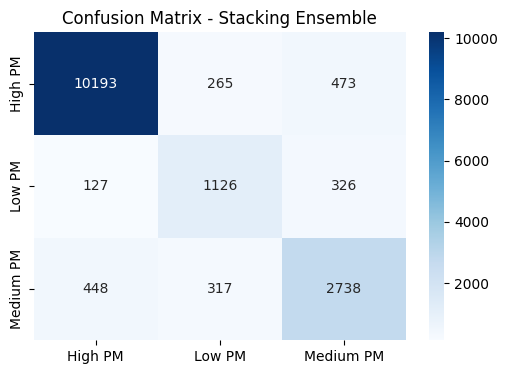

StackingClassifier(estimators=[('rf',
                                RandomForestClassifier(class_weight='balanced',
                                                       max_depth=20,
                                                       min_samples_split=10,
                                                       n_estimators=300,
                                                       n_jobs=-1,
                                                       random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=0.8, device=None,
                                              early_stopping_rounds=None,
                                              enable_categorica...
                                              max_delta_step=None, max_depth=10,
                                              max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=500, n_jobs=-1,
                                              num_class=3, ...)),
                               ('lgb',
                                LGBMClassifier(class_weight='balanced',
                                               learning_rate=0.05, max_depth=10,
                                               n_estimators=500, n_jobs=-1,
                                               random_state=42))],
                   final_estimator=LogisticRegression(max_iter=1000),
                   n_jobs=-1)

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

# -------------------------
# Stacking Classifier
# -------------------------
stacking_clf = StackingClassifier(
    estimators=[
        ('rf', rf),
        ('xgb', xgb_clf),
        ('lgb', lgb_clf)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    n_jobs=-1
)

evaluate_classification(stacking_clf, "Stacking Ensemble")

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Regression Performance (Stacking Ensemble - HI Prediction):
R² Score: 0.9990
MSE: 0.0018


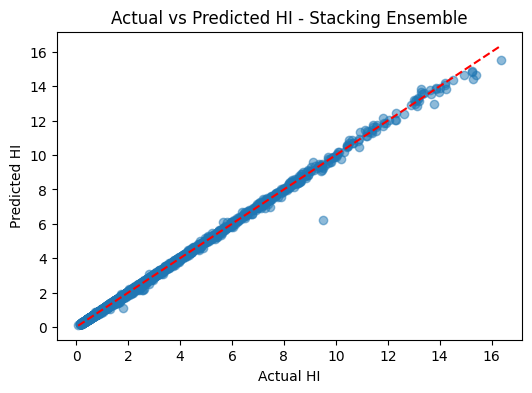

StackingRegressor(estimators=[('rf',
                               RandomForestRegressor(max_depth=15,
                                                     n_estimators=300,
                                                     n_jobs=-1,
                                                     random_state=42)),
                              ('xgb',
                               XGBRegressor(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.8, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None,
                                            feat...
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=10,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=500, n_jobs=-1,
                                            num_parallel_tree=None, ...)),
                              ('lgb',
                               LGBMRegressor(learning_rate=0.05, max_depth=10,
                                             n_estimators=500, n_jobs=-1,
                                             random_state=42))],
                  final_estimator=LinearRegression(), n_jobs=-1)

In [ ]:
from sklearn.ensemble import VotingRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression
# Stacking Regressor (BEST)
# -------------------------
stacking_reg = StackingRegressor(
    estimators=[
        ('rf', rf_reg),
        ('xgb', xgb_reg),
        ('lgb', lgb_reg)
    ],
    final_estimator=LinearRegression(),
    n_jobs=-1
)

evaluate_regression(stacking_reg, "Stacking Ensemble")

In [ ]:
from sklearn.model_selection import cross_val_score

print("\n🔁 5-Fold Cross-Validation (Stacking Ensemble):")

cv_scores_stack = cross_val_score(
    stacking_clf,
    X_scaled,
    y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

print("Scores:", cv_scores_stack)
print(f"Mean Accuracy: {cv_scores_stack.mean():.4f}")
print(f"Std Dev: {cv_scores_stack.std():.4f}")


🔁 5-Fold Cross-Validation (Stacking Ensemble):


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Scores: [0.7598826  0.77449572 0.68257041 0.63485918 0.71796153]
Mean Accuracy: 0.7140
Std Dev: 0.0511


Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7912 - loss: 0.4906 - val_accuracy: 0.8298 - val_loss: 0.4153
Epoch 2/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8284 - loss: 0.4149 - val_accuracy: 0.8407 - val_loss: 0.3845
Epoch 3/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8349 - loss: 0.3958 - val_accuracy: 0.8453 - val_loss: 0.3706
Epoch 4/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8395 - loss: 0.3829 - val_accuracy: 0.8443 - val_loss: 0.3649
Epoch 5/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8418 - loss: 0.3748 - val_accuracy: 0.8466 - val_loss: 0.3613
Epoch 6/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8440 - loss: 0.3698 - val_accuracy: 0.8532 - val_loss: 0.3530
Epoch 7/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8441 - loss: 0.3671 - val_accuracy: 0.8533 - val_loss: 0.3517
Epoch 8/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8466 - loss: 0.3628 - val_accurac

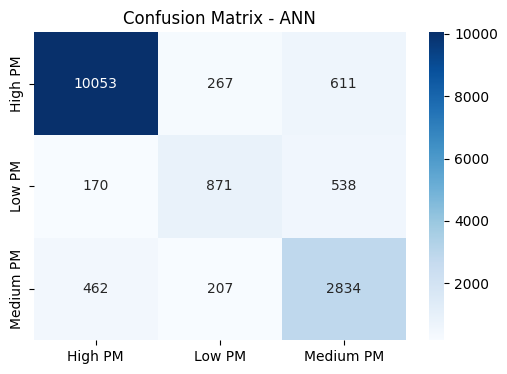

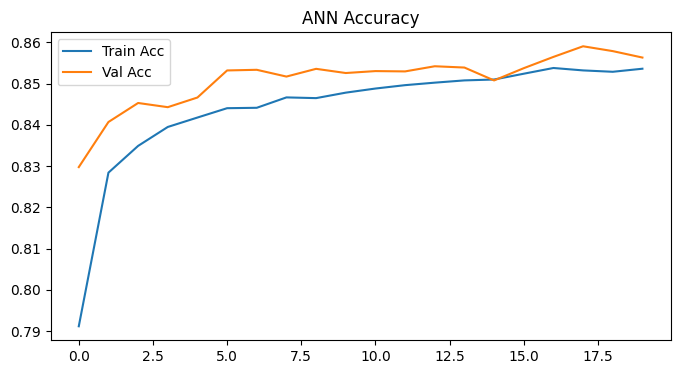

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1602/1602 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7932 - loss: 0.4882 - val_accuracy: 0.8255 - val_loss: 0.4218
Epoch 2/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8286 - loss: 0.4172 - val_accuracy: 0.8366 - val_loss: 0.3958
Epoch 3/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8366 - loss: 0.3956 - val_accuracy: 0.8385 - val_loss: 0.3830
Epoch 4/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8395 - loss: 0.3853 - val_accuracy: 0.8422 - val_loss: 0.3736
Epoch 5/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8428 - loss: 0.3788 - val_accuracy: 0.8448 - val_loss: 0.3695
Epoch 6/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8430 - loss: 0.3758 - val_accuracy: 0.8461 - val_loss: 0.3693
Epoch 7/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8447 - loss: 0.3709 - val_accuracy: 0.8491 - val_loss: 0.3630
Epoch 8/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8455 - loss: 0.3681 - val_accur

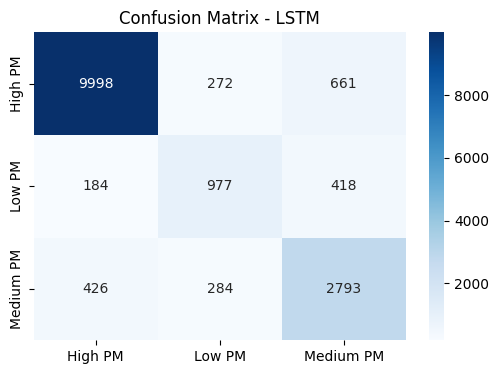

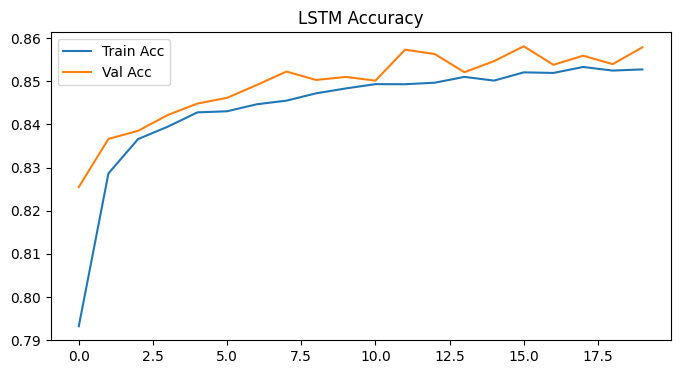

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1602/1602 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7968 - loss: 0.4805 - val_accuracy: 0.8256 - val_loss: 0.4137
Epoch 2/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8324 - loss: 0.4073 - val_accuracy: 0.8355 - val_loss: 0.3871
Epoch 3/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8369 - loss: 0.3920 - val_accuracy: 0.8432 - val_loss: 0.3761
Epoch 4/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8409 - loss: 0.3836 - val_accuracy: 0.8460 - val_loss: 0.3672
Epoch 5/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8431 - loss: 0.3778 - val_accuracy: 0.8472 - val_loss: 0.3665
Epoch 6/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8432 - loss: 0.3739 - val_accuracy: 0.8479 - val_loss: 0.3619
Epoch 7/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8441 - loss: 0.3711 - val_accuracy: 0.8486 - val_loss: 0.3611
Epoch 8/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8456 - loss: 0.3686 - val_accurac

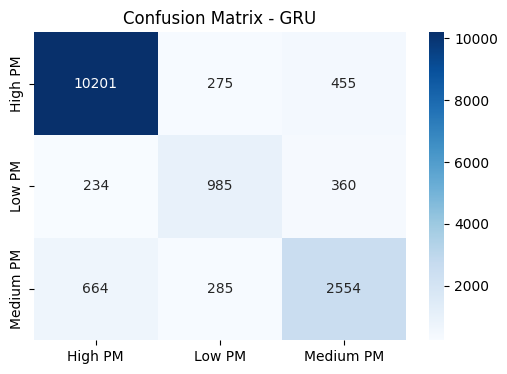

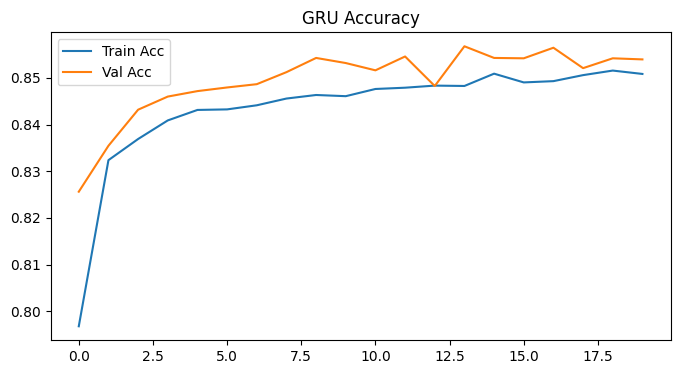

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1602/1602 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7859 - loss: 0.4958 - val_accuracy: 0.8234 - val_loss: 0.4258
Epoch 2/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8238 - loss: 0.4263 - val_accuracy: 0.8379 - val_loss: 0.3989
Epoch 3/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8291 - loss: 0.4094 - val_accuracy: 0.8384 - val_loss: 0.3885
Epoch 4/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8357 - loss: 0.3978 - val_accuracy: 0.8436 - val_loss: 0.3802
Epoch 5/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8383 - loss: 0.3911 - val_accuracy: 0.8424 - val_loss: 0.3748
Epoch 6/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8388 - loss: 0.3865 - val_accuracy: 0.8488 - val_loss: 0.3695
Epoch 7/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8406 - loss: 0.3822 - val_accuracy: 0.8501 - val_loss: 0.3673
Epoch 8/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8427 - loss: 0.3776 - val_accura

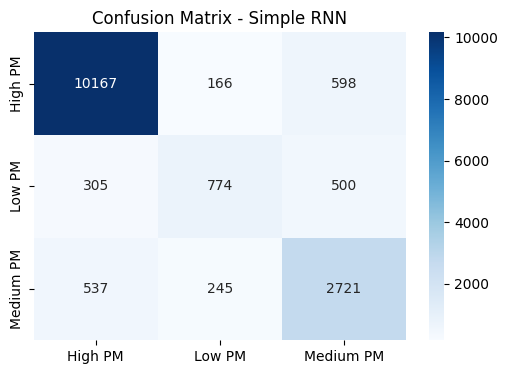

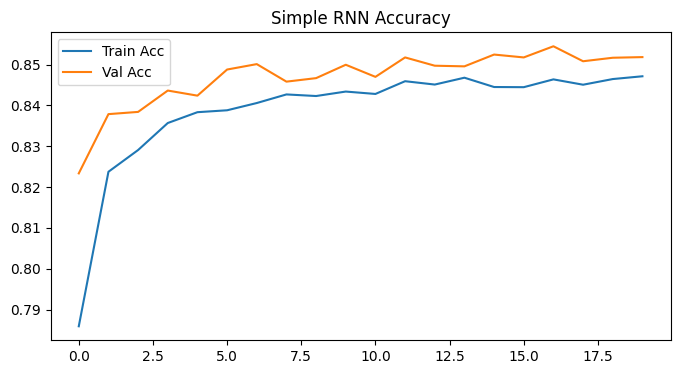

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1602/1602 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7740 - loss: 0.5238 - val_accuracy: 0.8244 - val_loss: 0.4309
Epoch 2/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8144 - loss: 0.4419 - val_accuracy: 0.8345 - val_loss: 0.3993
Epoch 3/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8293 - loss: 0.4130 - val_accuracy: 0.8446 - val_loss: 0.3807
Epoch 4/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8351 - loss: 0.3987 - val_accuracy: 0.8444 - val_loss: 0.3744
Epoch 5/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8372 - loss: 0.3915 - val_accuracy: 0.8454 - val_loss: 0.3691
Epoch 6/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8390 - loss: 0.3850 - val_accuracy: 0.8495 - val_loss: 0.3656
Epoch 7/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8420 - loss: 0.3810 - val_accuracy: 0.8493 - val_loss: 0.3631
Epoch 8/20
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8419 - loss: 0.3788 - val_accurac

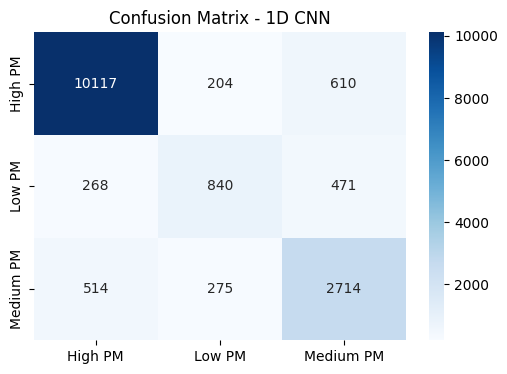

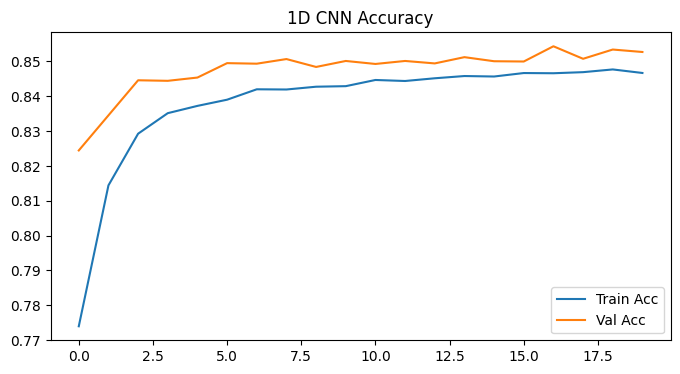

<Sequential name=sequential_4, built=True>

In [ ]:
# =========================
# Deep Learning Classification
# =========================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, GRU, SimpleRNN, Conv1D, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# -------------------------
# One-hot encode target
# -------------------------
y_train_cat = to_categorical(y_train, num_classes=len(le.classes_))
y_test_cat = to_categorical(y_test, num_classes=len(le.classes_))

# -------------------------
# Reshape for sequence models
# -------------------------
X_train_seq = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_seq = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

X_train_rnn = X_train_seq.copy()
X_test_rnn = X_test_seq.copy()

X_train_cnn = X_train_seq.copy()
X_test_cnn = X_test_seq.copy()

# -------------------------
# Helper function for DL classification
# -------------------------
def evaluate_dl_model(model, name, X_train_in, X_test_in):
    history = model.fit(
        X_train_in, y_train_cat,
        epochs=20, batch_size=32, validation_split=0.2,
        verbose=1
    )

    # Predictions
    y_pred_probs = model.predict(X_test_in)
    y_pred = np.argmax(y_pred_probs, axis=1)

    print(f"\nClassification Report ({name}):")
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    # Plot loss/accuracy
    plt.figure(figsize=(8,4))
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f"{name} Accuracy")
    plt.legend()
    plt.show()

    return model

# -------------------------
# ANN Model
# -------------------------
ann_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])
ann_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
evaluate_dl_model(ann_model, "ANN", X_train, X_test)

# -------------------------
# LSTM Model
# -------------------------
lstm_model = Sequential([
    LSTM(64, input_shape=(1, X_train.shape[1]), return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])
lstm_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
evaluate_dl_model(lstm_model, "LSTM", X_train_seq, X_test_seq)

# -------------------------
# GRU Model
# -------------------------
gru_model = Sequential([
    GRU(64, input_shape=(1, X_train.shape[1]), return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])
gru_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
evaluate_dl_model(gru_model, "GRU", X_train_seq, X_test_seq)

# -------------------------
# Simple RNN Model
# -------------------------
rnn_model = Sequential([
    SimpleRNN(64, input_shape=(1, X_train.shape[1]), return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])
rnn_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
evaluate_dl_model(rnn_model, "Simple RNN", X_train_rnn, X_test_rnn)

# -------------------------
# 1D CNN Model
# -------------------------
cnn_model = Sequential([
    Conv1D(64, kernel_size=1, activation='relu', input_shape=(1, X_train.shape[1])),
    Dropout(0.3),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])
cnn_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
evaluate_dl_model(cnn_model, "1D CNN", X_train_cnn, X_test_cnn)


In [ ]:
# =========================
# 📦 Imports
# =========================
import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

# =========================
# 🎯 Step 1: Predictions
# =========================

# Convert y_test → NumPy (FIX for KeyError)
y_true = np.array(y_test)

# ANN
y_pred_ann = np.argmax(ann_model.predict(X_test, verbose=0), axis=1)

# LSTM
y_pred_lstm = np.argmax(lstm_model.predict(X_test_seq, verbose=0), axis=1)

# GRU
y_pred_gru = np.argmax(gru_model.predict(X_test_seq, verbose=0), axis=1)

# Simple RNN
y_pred_rnn = np.argmax(rnn_model.predict(X_test_seq, verbose=0), axis=1)

# CNN
y_pred_cnn = np.argmax(cnn_model.predict(X_test_seq, verbose=0), axis=1)

# =========================
# 📊 Step 2: McNemar Function (FIXED)
# =========================

def mcnemar_test(y_true, y_pred1, y_pred2, model1_name, model2_name):

    # Ensure NumPy arrays (FIX)
    y_true = np.array(y_true)
    y_pred1 = np.array(y_pred1)
    y_pred2 = np.array(y_pred2)

    # Initialize counts
    n01 = 0  # model1 correct, model2 wrong
    n10 = 0  # model1 wrong, model2 correct

    # Loop safely using index
    for i in range(len(y_true)):
        correct1 = (y_pred1[i] == y_true[i])
        correct2 = (y_pred2[i] == y_true[i])

        if correct1 and not correct2:
            n01 += 1
        elif not correct1 and correct2:
            n10 += 1

    # Build contingency table
    table = [[0, n01],
             [n10, 0]]

    # Apply McNemar test
    result = mcnemar(table, exact=True)

    # Output
    print("\n" + "="*50)
    print(f"📊 McNemar Test: {model1_name} vs {model2_name}")
    print(f"n01 (Model1 correct, Model2 wrong): {n01}")
    print(f"n10 (Model1 wrong, Model2 correct): {n10}")
    print(f"p-value: {result.pvalue:.6f}")

    if result.pvalue < 0.05:
        print("✅ Significant difference (Reject H0)")
    else:
        print("❌ No significant difference (Fail to reject H0)")

# =========================
# 🔁 Step 3: Run All Comparisons
# =========================

# ANN vs Others
mcnemar_test(y_true, y_pred_ann, y_pred_lstm, "ANN", "LSTM")
mcnemar_test(y_true, y_pred_ann, y_pred_gru, "ANN", "GRU")
mcnemar_test(y_true, y_pred_ann, y_pred_rnn, "ANN", "Simple RNN")
mcnemar_test(y_true, y_pred_ann, y_pred_cnn, "ANN", "1D CNN")

# LSTM vs Others
mcnemar_test(y_true, y_pred_lstm, y_pred_gru, "LSTM", "GRU")
mcnemar_test(y_true, y_pred_lstm, y_pred_rnn, "LSTM", "Simple RNN")
mcnemar_test(y_true, y_pred_lstm, y_pred_cnn, "LSTM", "1D CNN")

# GRU vs Others
mcnemar_test(y_true, y_pred_gru, y_pred_rnn, "GRU", "Simple RNN")
mcnemar_test(y_true, y_pred_gru, y_pred_cnn, "GRU", "1D CNN")

# RNN vs CNN
mcnemar_test(y_true, y_pred_rnn, y_pred_cnn, "Simple RNN", "1D CNN")


📊 McNemar Test: ANN vs LSTM
n01 (Model1 correct, Model2 wrong): 322
n10 (Model1 wrong, Model2 correct): 332
p-value: 0.724922
❌ No significant difference (Fail to reject H0)

📊 McNemar Test: ANN vs GRU
n01 (Model1 correct, Model2 wrong): 408
n10 (Model1 wrong, Model2 correct): 390
p-value: 0.547338
❌ No significant difference (Fail to reject H0)

📊 McNemar Test: ANN vs Simple RNN
n01 (Model1 correct, Model2 wrong): 457
n10 (Model1 wrong, Model2 correct): 361
p-value: 0.000884
✅ Significant difference (Reject H0)

📊 McNemar Test: ANN vs 1D CNN
n01 (Model1 correct, Model2 wrong): 424
n10 (Model1 wrong, Model2 correct): 337
p-value: 0.001806
✅ Significant difference (Reject H0)

📊 McNemar Test: LSTM vs GRU
n01 (Model1 correct, Model2 wrong): 389
n10 (Model1 wrong, Model2 correct): 361
p-value: 0.324183
❌ No significant difference (Fail to reject H0)

📊 McNemar Test: LSTM vs Simple RNN
n01 (Model1 correct, Model2 wrong): 463
n10 (Model1 wrong, Model2 correct): 357
p-value: 0.000241
✅ Sign

In [ ]:
# =========================
# 📦 Imports
# =========================
import numpy as np
import random
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, GRU, SimpleRNN, Conv1D, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

# -------------------------
# Reproducibility
# -------------------------
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

# -------------------------
# Prepare Data
# -------------------------
X_np = X.to_numpy()   # convert DataFrame → NumPy
y_cat = to_categorical(y, num_classes=len(le.classes_))

# Sequence data (for LSTM, GRU, RNN, CNN)
X_seq = X_np.reshape((X_np.shape[0], 1, X_np.shape[1]))

# -------------------------
# K-Fold Setup
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# =========================
# 🧠 Model Builders
# =========================

def build_ann(input_dim, num_classes):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
    return model

def build_lstm(input_shape, num_classes):
    model = Sequential([
        LSTM(64, input_shape=input_shape),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
    return model

def build_gru(input_shape, num_classes):
    model = Sequential([
        GRU(64, input_shape=input_shape),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
    return model

def build_rnn(input_shape, num_classes):
    model = Sequential([
        SimpleRNN(64, input_shape=input_shape),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
    return model

def build_cnn(input_shape, num_classes):
    model = Sequential([
        Conv1D(64, kernel_size=1, activation='relu', input_shape=input_shape),
        Dropout(0.3),
        Flatten(),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
    return model

# =========================
# 🔁 Cross-Validation Function
# =========================

def cross_validate_dl(build_model_fn, X_data, y_data, name, epochs=20, batch_size=32):
    fold_acc = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_data)):
        print(f"\n🔁 Fold {fold+1}/{kf.n_splits} - {name}")

        X_train_fold, X_val_fold = X_data[train_idx], X_data[val_idx]
        y_train_fold, y_val_fold = y_data[train_idx], y_data[val_idx]

        # Correct input shape handling
        if len(X_train_fold.shape) == 2:  # ANN
            input_shape = X_train_fold.shape[1]
        else:  # Sequence models
            input_shape = X_train_fold.shape[1:]

        model = build_model_fn(input_shape, y_data.shape[1])

        model.fit(
            X_train_fold, y_train_fold,
            epochs=epochs,
            batch_size=batch_size,
            validation_data=(X_val_fold, y_val_fold),
            verbose=0
        )

        # Prediction
        y_pred_probs = model.predict(X_val_fold, verbose=0)
        y_pred = np.argmax(y_pred_probs, axis=1)
        y_true = np.argmax(y_val_fold, axis=1)

        acc = accuracy_score(y_true, y_pred)
        fold_acc.append(acc)

        print(f"Accuracy: {acc:.4f}")

    print(f"\n✅ {name} - Mean Accuracy: {np.mean(fold_acc):.4f}, Std: {np.std(fold_acc):.4f}")
    return fold_acc

# =========================
# 🚀 Run All Models
# =========================

ann_acc = cross_validate_dl(build_ann, X_np, y_cat, "ANN")

lstm_acc = cross_validate_dl(build_lstm, X_seq, y_cat, "LSTM")

gru_acc = cross_validate_dl(build_gru, X_seq, y_cat, "GRU")

rnn_acc = cross_validate_dl(build_rnn, X_seq, y_cat, "Simple RNN")

cnn_acc = cross_validate_dl(build_cnn, X_seq, y_cat, "1D CNN")


🔁 Fold 1/5 - ANN


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy: 0.9537

🔁 Fold 2/5 - ANN


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy: 0.9402

🔁 Fold 3/5 - ANN


...

Accuracy: 0.9459

🔁 Fold 4/5 - 1D CNN


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy: 0.9406

🔁 Fold 5/5 - 1D CNN


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy: 0.9430

✅ 1D CNN - Mean Accuracy: 0.9495, Std: 0.0083


In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_score
from scipy.stats import wilcoxon

# =========================
# 1️⃣ Get CV Scores
# =========================

dt_scores  = cross_val_score(dt, X, y, cv=5)
rf_scores  = cross_val_score(rf, X, y, cv=5)
xgb_scores = cross_val_score(xgb_clf, X, y, cv=5)
lgb_scores = cross_val_score(lgb_clf, X, y, cv=5)
cat_scores = cross_val_score(cat_clf, X, y, cv=5)

# =========================
# 2️⃣ Print Basic Stats
# =========================

def print_stats(name, scores):
    print(f"{name}:")
    print(f" Scores: {scores}")
    print(f" Mean: {np.mean(scores):.4f}")
    print(f" Std: {np.std(scores):.4f}")
    print("-"*40)

print_stats("Decision Tree", dt_scores)
print_stats("Random Forest", rf_scores)
print_stats("XGBoost", xgb_scores)
print_stats("LightGBM", lgb_scores)
print_stats("CatBoost", cat_scores)

# =========================
# 3️⃣ Wilcoxon Function
# =========================

def wilcoxon_test(model1_scores, model2_scores, name1, name2):
    stat, p = wilcoxon(model1_scores, model2_scores)
    print(f"{name1} vs {name2}: p-value = {p:.4f}")

    if p < 0.05:
        print(" → Significant difference ✅")
    else:
        print(" → No significant difference ❌")
    print("-"*40)

# =========================
# 4️⃣ Pairwise Comparisons
# =========================

# Compare best model (example: CatBoost) with others
wilcoxon_test(cat_scores, dt_scores,  "CatBoost", "Decision Tree")
wilcoxon_test(cat_scores, rf_scores,  "CatBoost", "Random Forest")
wilcoxon_test(cat_scores, xgb_scores, "CatBoost", "XGBoost")
wilcoxon_test(cat_scores, lgb_scores, "CatBoost", "LightGBM")

# Optional: compare other pairs
wilcoxon_test(xgb_scores, rf_scores, "XGBoost", "Random Forest")
wilcoxon_test(lgb_scores, rf_scores, "LightGBM", "Random Forest")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004467 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 16
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003122 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4296
[LightGBM] [Info] Number of data points in the train set: 64051, 

In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_score
from scipy.stats import wilcoxon
from sklearn.svm import SVC   # ✅ Added

# =========================
# 1️⃣ Get CV Scores
# =========================

dt_scores  = cross_val_score(dt, X, y, cv=5)
rf_scores  = cross_val_score(rf, X, y, cv=5)
xgb_scores = cross_val_score(xgb_clf, X, y, cv=5)
lgb_scores = cross_val_score(lgb_clf, X, y, cv=5)

# ✅ SVM added
svm_clf = SVC(
    kernel='rbf',
    C=10,
    gamma=0.1,
    class_weight='balanced',
    random_state=42
)
svm_scores = cross_val_score(svm_clf, X, y, cv=5)

# =========================
# 2️⃣ Print Basic Stats
# =========================

def print_stats(name, scores):
    print(f"{name}:")
    print(f" Scores: {scores}")
    print(f" Mean: {np.mean(scores):.4f}")
    print(f" Std: {np.std(scores):.4f}")
    print("-"*40)

print_stats("Decision Tree", dt_scores)
print_stats("Random Forest", rf_scores)
print_stats("XGBoost", xgb_scores)
print_stats("LightGBM", lgb_scores)
print_stats("SVM", svm_scores)   # ✅ updated

# =========================
# 3️⃣ Wilcoxon Function
# =========================

def wilcoxon_test(model1_scores, model2_scores, name1, name2):
    stat, p = wilcoxon(model1_scores, model2_scores)
    print(f"{name1} vs {name2}: p-value = {p:.4f}")

    if p < 0.05:
        print(" → Significant difference ✅")
    else:
        print(" → No significant difference ❌")
    print("-"*40)

# =========================
# 4️⃣ Pairwise Comparisons
# =========================

# ✅ Compare SVM with others (replacing CatBoost)
wilcoxon_test(svm_scores, dt_scores,  "SVM", "Decision Tree")
wilcoxon_test(svm_scores, rf_scores,  "SVM", "Random Forest")
wilcoxon_test(svm_scores, xgb_scores, "SVM", "XGBoost")
wilcoxon_test(svm_scores, lgb_scores, "SVM", "LightGBM")

# Optional: compare other pairs (unchanged)
wilcoxon_test(xgb_scores, rf_scores, "XGBoost", "Random Forest")
wilcoxon_test(lgb_scores, rf_scores, "LightGBM", "Random Forest")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005018 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 16
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003355 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4296
[LightGBM] [Info] Number of data points in the train set: 64051, 

In [ ]:
# =========================
# 📦 Imports
# =========================
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from scipy.stats import wilcoxon

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# =========================
# 🔁 K-Fold Setup
# =========================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Store scores
model_scores = {}

# =========================
# 📊 Cross Validation Function
# =========================
def cross_validate_regressor(model, name):
    scores = cross_val_score(
        model,
        X_scaled,     # your features
        y_reg,        # your regression target
        cv=kf,
        scoring='r2',
        n_jobs=-1
    )

    model_scores[name] = scores  # store scores

    print(f"\n🔁 5-Fold CV ({name})")
    print("R² Scores:", scores)
    print(f"Mean R²: {np.mean(scores):.4f}")
    print(f"Std Dev: {np.std(scores):.4f}")
    print("-"*50)

# =========================
# 🧠 Run All Models
# =========================

cross_validate_regressor(
    DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=42),
    "Decision Tree"
)

cross_validate_regressor(
    RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1),
    "Random Forest"
)

cross_validate_regressor(
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost"
)

cross_validate_regressor(
    LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM"
)

cross_validate_regressor(
    CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=10,
        loss_function='RMSE',
        random_seed=42,
        verbose=0
    ),
    "CatBoost"
)

# =========================
# 📈 Wilcoxon Test Function
# =========================
def wilcoxon_test(scores1, scores2, name1, name2):
    stat, p = wilcoxon(scores1, scores2)

    print(f"\n📊 {name1} vs {name2}")
    print(f"p-value: {p:.4f}")

    if p < 0.05:
        print("✅ Significant difference")
    else:
        print("❌ No significant difference")
    print("-"*50)

# =========================
# 🧪 Pairwise Comparisons
# =========================

# Compare CatBoost (or best model) with others
wilcoxon_test(model_scores["CatBoost"], model_scores["Decision Tree"], "CatBoost", "Decision Tree")
wilcoxon_test(model_scores["CatBoost"], model_scores["Random Forest"], "CatBoost", "Random Forest")
wilcoxon_test(model_scores["CatBoost"], model_scores["XGBoost"], "CatBoost", "XGBoost")
wilcoxon_test(model_scores["CatBoost"], model_scores["LightGBM"], "CatBoost", "LightGBM")

# Optional extra comparisons
wilcoxon_test(model_scores["XGBoost"], model_scores["Random Forest"], "XGBoost", "Random Forest")
wilcoxon_test(model_scores["LightGBM"], model_scores["Random Forest"], "LightGBM", "Random Forest")


🔁 5-Fold CV (Decision Tree)
R² Scores: [0.99738603 0.99772565 0.99755048 0.99774583 0.99739448]
Mean R²: 0.9976
Std Dev: 0.0002
--------------------------------------------------


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



🔁 5-Fold CV (Random Forest)
R² Scores: [0.99881541 0.99921448 0.99908164 0.99926959 0.99881807]
Mean R²: 0.9990
Std Dev: 0.0002
--------------------------------------------------

🔁 5-Fold CV (XGBoost)
R² Scores: [0.99494982 0.99325549 0.99600352 0.99558008 0.99488641]
Mean R²: 0.9949
Std Dev: 0.0009
--------------------------------------------------

🔁 5-Fold CV (LightGBM)
R² Scores: [0.99692213 0.99697653 0.99733699 0.99706529 0.99674506]
Mean R²: 0.9970
Std Dev: 0.0002
--------------------------------------------------

🔁 5-Fold CV (CatBoost)
R² Scores: [0.99562554 0.99630586 0.99736299 0.99774228 0.99667502]
Mean R²: 0.9967
Std Dev: 0.0008
--------------------------------------------------

📊 CatBoost vs Decision Tree
p-value: 0.0625
❌ No significant difference
--------------------------------------------------

📊 CatBoost vs Random Forest
p-value: 0.0625
❌ No significant difference
--------------------------------------------------

📊 CatBoost vs XGBoost
p-value: 0.0625
❌ No sign

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80064 entries, 0 to 80063
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          80064 non-null  object 
 1   Time          71592 non-null  object 
 2   SO2           80064 non-null  float64
 3   NO            80064 non-null  float64
 4   NO2           80064 non-null  float64
 5   NOX           80064 non-null  float64
 6   CO            80064 non-null  float64
 7   CO 8hr        80064 non-null  float64
 8   O3            80064 non-null  float64
 9   O3 8hr        80064 non-null  float64
 10  PM2.5         80064 non-null  float64
 11  PM10          80064 non-null  float64
 12  Wind Speed    80064 non-null  float64
 13  Wind Dir      80064 non-null  float64
 14  Temperature   80064 non-null  float64
 15  RH            80064 non-null  float64
 16  Solar Rad     80064 non-null  float64
 17  BP            80064 non-null  float64
 18  Rain          80064 non-nu

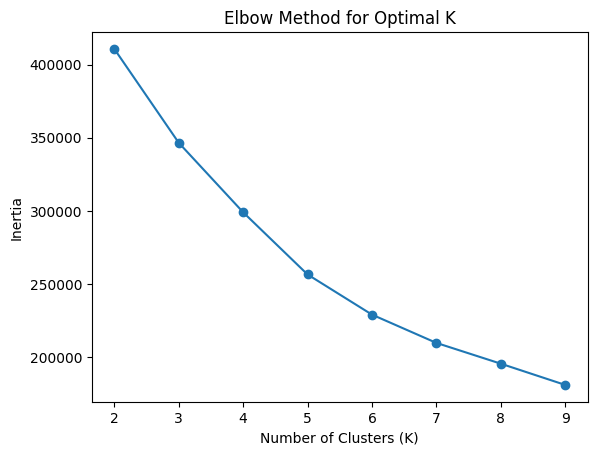

K=2, Silhouette Score=0.6435
K=3, Silhouette Score=0.5083
K=4, Silhouette Score=0.4371
K=5, Silhouette Score=0.4509
K=6, Silhouette Score=0.2738
K=7, Silhouette Score=0.2794
K=8, Silhouette Score=0.3006
K=9, Silhouette Score=0.3134

Cluster-wise Mean Values:
              PM2.5         NOX        NO2        SO2        CO         O3  \
Cluster                                                                      
0        118.716813   51.940941  20.557331   4.543847  4.463984   5.243514   
1         96.081618  211.340861  30.962943  17.185613  3.708324   9.191731   
2         44.133086   16.715691   8.532735   4.355092  2.176043  10.118998   

               HI  
Cluster            
0        2.720805  
1        8.805698  
2        1.109110  


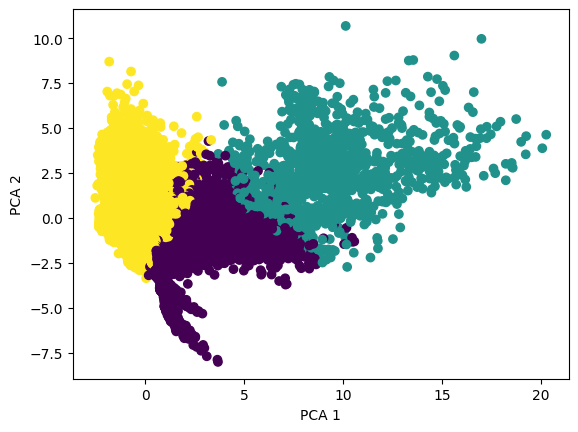


Cluster Centers (Original Scale):
        PM2.5         NOX        NO2        SO2        CO         O3        HI
0  118.667729   51.878531  20.551130   4.542444  4.461365   5.249232  2.718498
1   96.171265  211.251127  30.948953  17.172138  3.710025   9.182501  8.801718
2   44.122768   16.713934   8.530961   4.355138  2.175906  10.119310  1.108985


In [ ]:
# =========================
# 📦 Imports
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# =========================
# 📊 Select Features
# =========================
features = ['PM2.5', 'NOX', 'NO2', 'SO2', 'CO', 'O3', 'HI']  # or HQ
X = df[features]

# =========================
# ⚖️ Feature Scaling (VERY IMPORTANT)
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================
# 📉 Elbow Method (Find Optimal K)
# =========================
inertia = []

K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure()
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

# =========================
# 📈 Silhouette Score (Better validation)
# =========================
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"K={k}, Silhouette Score={score:.4f}")

# =========================
# 🚀 Apply K-Means (Choose Best K, e.g., 3)
# =========================
optimal_k = 3  # change based on elbow/silhouette

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataframe
df['Cluster'] = clusters

# =========================
# 📊 Cluster Analysis (MOST IMPORTANT PART)
# =========================
cluster_summary = df.groupby('Cluster')[features].mean()
print("\nCluster-wise Mean Values:")
print(cluster_summary)

# =========================
# 🎯 Label Clusters (Optional but powerful)
# =========================
# You can manually interpret clusters based on HI
# Example:
# Cluster 0 -> Low Risk
# Cluster 1 -> Medium Risk
# Cluster 2 -> High Risk

# =========================
# 📉 PCA Visualization (2D)
# =========================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

# =========================
# 📍 Cluster Centers (Important for thesis)
# =========================
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers, columns=features)

print("\nCluster Centers (Original Scale):")
print(centers_df)

In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_score
from scipy.stats import wilcoxon

# =========================
# 1️⃣ Get CV Scores
# =========================

dt_scores  = cross_val_score(dt, X, y, cv=5)
rf_scores  = cross_val_score(rf, X, y, cv=5)
xgb_scores = cross_val_score(xgb_clf, X, y, cv=5)
lgb_scores = cross_val_score(lgb_clf, X, y, cv=5)

# =========================
# 2️⃣ Print Basic Stats
# =========================

def print_stats(name, scores):
    print(f"{name}:")
    print(f" Scores: {scores}")
    print(f" Mean: {np.mean(scores):.4f}")
    print(f" Std: {np.std(scores):.4f}")
    print("-"*40)

print_stats("Decision Tree", dt_scores)
print_stats("Random Forest", rf_scores)
print_stats("XGBoost", xgb_scores)
print_stats("LightGBM", lgb_scores)

# =========================
# 3️⃣ Wilcoxon Function
# =========================

def wilcoxon_test(model1_scores, model2_scores, name1, name2):
    stat, p = wilcoxon(model1_scores, model2_scores)
    print(f"{name1} vs {name2}: p-value = {p:.4f}")

    if p < 0.05:
        print(" → Significant difference ✅")
    else:
        print(" → No significant difference ❌")
    print("-"*40)

# =========================
# 4️⃣ Pairwise Comparisons
# =========================

# Compare strong models
wilcoxon_test(xgb_scores, rf_scores, "XGBoost", "Random Forest")
wilcoxon_test(lgb_scores, rf_scores, "LightGBM", "Random Forest")
wilcoxon_test(xgb_scores, lgb_scores, "XGBoost", "LightGBM")

# Optional: baseline comparisons
wilcoxon_test(dt_scores, rf_scores, "Decision Tree", "Random Forest")
wilcoxon_test(dt_scores, xgb_scores, "Decision Tree", "XGBoost")
wilcoxon_test(dt_scores, lgb_scores, "Decision Tree", "LightGBM")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.017745 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 16
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003229 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4296
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 17
[LightGBM] [Info] Start training fro

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005792 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 64051, number of used features: 16
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003414 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4296
[LightGBM] [Info] Number of data points in the train set: 64051, 

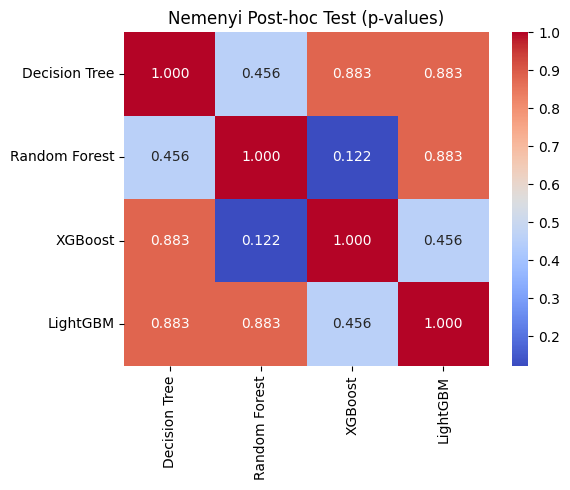


📊 Average Ranks (Lower = Better):
Decision Tree: 2.80
Random Forest: 1.60
XGBoost: 3.40
LightGBM: 2.20


In [ ]:

!pip install -q scikit-posthocs
# =========================
# 📦 Imports
# =========================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score
from scipy.stats import friedmanchisquare
import scikit_posthocs as sp

# =========================
# 1️⃣ Cross-validation scores
# =========================

cv = 5  # you can change to 10 or RepeatedKFold for stronger results

dt_scores  = cross_val_score(dt, X, y, cv=cv)
rf_scores  = cross_val_score(rf, X, y, cv=cv)
xgb_scores = cross_val_score(xgb_clf, X, y, cv=cv)
lgb_scores = cross_val_score(lgb_clf, X, y, cv=cv)

# =========================
# 2️⃣ Print statistics
# =========================

def print_stats(name, scores):
    print(f"{name}:")
    print(f" Scores: {scores}")
    print(f" Mean: {np.mean(scores):.4f}")
    print(f" Std: {np.std(scores):.4f}")
    print("-"*40)

print_stats("Decision Tree", dt_scores)
print_stats("Random Forest", rf_scores)
print_stats("XGBoost", xgb_scores)
print_stats("LightGBM", lgb_scores)

# =========================
# 3️⃣ Prepare data for Friedman test
# =========================
# Rows = folds, Columns = models

scores_matrix = np.vstack([
    dt_scores,
    rf_scores,
    xgb_scores,
    lgb_scores
]).T

# =========================
# 4️⃣ Friedman Test
# =========================

stat, p = friedmanchisquare(dt_scores, rf_scores, xgb_scores, lgb_scores)

print("\n📊 Friedman Test Result:")
print(f"Statistic = {stat:.4f}, p-value = {p:.4f}")

if p < 0.05:
    print(" → Significant differences exist between models ✅")
else:
    print(" → No significant differences detected ❌")

# =========================
# 5️⃣ Nemenyi Post-hoc Test
# =========================

nemenyi_result = sp.posthoc_nemenyi_friedman(scores_matrix)

model_names = ["Decision Tree", "Random Forest", "XGBoost", "LightGBM"]

nemenyi_result.columns = model_names
nemenyi_result.index = model_names

print("\n📊 Nemenyi Post-hoc Test (p-values):")
print(nemenyi_result)

# =========================
# 6️⃣ Heatmap Visualization
# =========================

plt.figure(figsize=(6,5))
sns.heatmap(nemenyi_result, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Nemenyi Post-hoc Test (p-values)")
plt.tight_layout()
plt.show()

# =========================
# 7️⃣ (Optional) Rank Visualization
# =========================

# Compute average ranks (lower rank = better performance)
ranks = np.argsort(np.argsort(-scores_matrix, axis=1), axis=1) + 1
avg_ranks = np.mean(ranks, axis=0)

print("\n📊 Average Ranks (Lower = Better):")
for name, rank in zip(model_names, avg_ranks):
    print(f"{name}: {rank:.2f}")


In [ ]:
!pip install -q scikit-posthocs

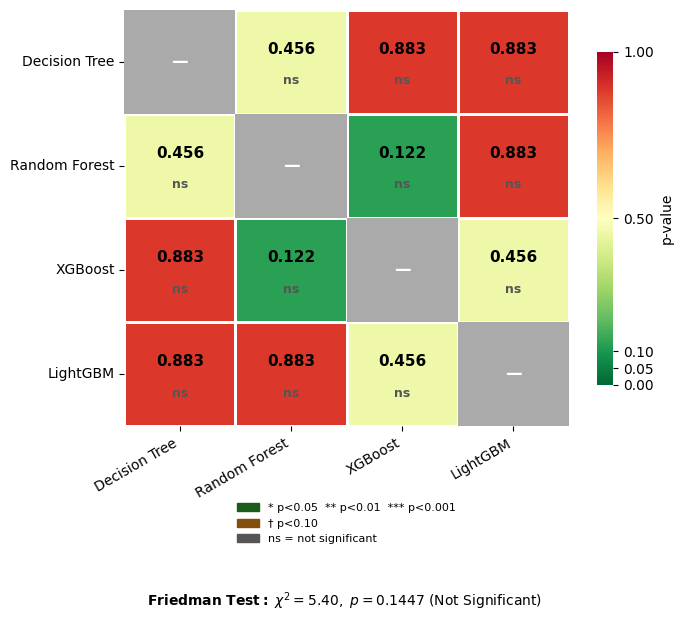

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ============================================================
# Classification Nemenyi Heatmap + Friedman Result
# ============================================================

def plot_classification_heatmap(
        nemenyi_result,
        filename='fig_nemenyi_classification.tiff',
        figsize=(7,6.3)):

    matrix = nemenyi_result.values
    model_names = list(nemenyi_result.columns)
    n = len(model_names)

    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        matrix,
        annot=False,
        cmap='RdYlGn_r',
        vmin=0,
        vmax=1,
        xticklabels=model_names,
        yticklabels=model_names,
        linewidths=0.8,
        linecolor='white',
        cbar_kws={
            'label':'p-value',
            'shrink':0.8,
            'ticks':[0,0.05,0.10,0.5,1.0]
        },
        ax=ax
    )

    # ---------- annotations ----------
    for i in range(n):
        for j in range(n):

            p = matrix[i,j]

            if i == j:

                ax.add_patch(
                    plt.Rectangle(
                        (j,i),1,1,
                        color='#AAAAAA',
                        lw=0,
                        zorder=2
                    )
                )

                ax.text(
                    j+0.5,i+0.5,'—',
                    ha='center',
                    va='center',
                    fontsize=12,
                    color='white',
                    fontweight='bold'
                )

            else:

                ax.text(
                    j+0.5,
                    i+0.38,
                    f'{p:.3f}',
                    ha='center',
                    va='center',
                    fontsize=11,
                    fontweight='bold'
                )

                if p < 0.001:
                    marker='***'
                    color='#1A5C1A'
                elif p < 0.01:
                    marker='**'
                    color='#1A5C1A'
                elif p < 0.05:
                    marker='*'
                    color='#1A5C1A'
                elif p < 0.10:
                    marker='†'
                    color='#854F0B'
                else:
                    marker='ns'
                    color='#555555'

                ax.text(
                    j+0.5,
                    i+0.68,
                    marker,
                    ha='center',
                    va='center',
                    fontsize=9,
                    color=color,
                    fontweight='bold'
                )

    ax.set_xticklabels(
        model_names,
        rotation=30,
        ha='right',
        fontsize=10
    )

    ax.set_yticklabels(
        model_names,
        rotation=0,
        fontsize=10
    )

    # ---------- legend ----------
    legend_elements = [
        mpatches.Patch(color='#1A5C1A',
                       label='* p<0.05  ** p<0.01  *** p<0.001'),
        mpatches.Patch(color='#854F0B',
                       label='† p<0.10'),
        mpatches.Patch(color='#555555',
                       label='ns = not significant')
    ]

    ax.legend(
        handles=legend_elements,
        loc='upper center',
        bbox_to_anchor=(0.5,-0.16),
        frameon=False,
        fontsize=8
    )

    # =====================================================
    # Friedman Test Result (below heatmap)
    # =====================================================
    fig.text(
        0.5,
        0.03,
        r'$\bf{Friedman\ Test:}$ '
        r'$\chi^2 = 5.40,\ p = 0.1447$ (Not Significant)',
        ha='center',
        fontsize=10
    )

    plt.tight_layout(rect=[0,0.08,1,1])

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches='tight',
        format='tiff'
    )

    plt.show()


# ============================================================
# Run
# ============================================================

plot_classification_heatmap(
    nemenyi_result,
    filename='fig_nemenyi_classification.tiff'
)

Saved: fig_nemenyi_classification.tiff


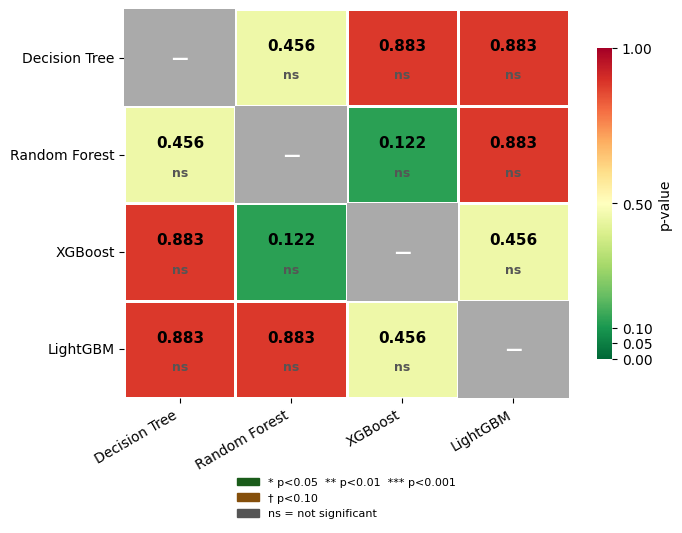

Saved: fig_nemenyi_regression.tiff


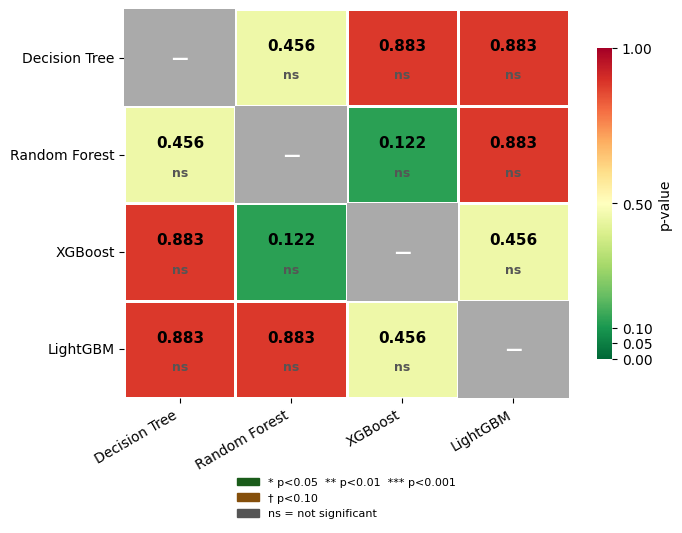

NameError: name 'nemenyi_cls' is not defined

In [ ]:
# ============================================================
# CELL 1 — Import required libraries
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np

# ============================================================
# CELL 2 — Reusable function for both heatmaps
# ============================================================

def plot_nemenyi_heatmap(
        nemenyi_result,
        filename,
        figsize=(7,5.5)):
    """
    Publication-quality Nemenyi heatmap
    (without title/subtitle)
    """

    matrix = nemenyi_result.values
    model_names = list(nemenyi_result.columns)
    n = len(model_names)

    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        matrix,
        annot=False,
        cmap='RdYlGn_r',
        vmin=0,
        vmax=1,
        xticklabels=model_names,
        yticklabels=model_names,
        linewidths=0.8,
        linecolor='white',
        cbar_kws={
            'label':'p-value',
            'shrink':0.8,
            'ticks':[0,0.05,0.10,0.5,1.0]
        },
        ax=ax
    )

    for i in range(n):
        for j in range(n):

            p = matrix[i,j]

            if i==j:

                ax.add_patch(
                    plt.Rectangle(
                        (j,i),
                        1,
                        1,
                        color='#AAAAAA',
                        lw=0,
                        zorder=2
                    )
                )

                ax.text(
                    j+0.5,
                    i+0.5,
                    '—',
                    ha='center',
                    va='center',
                    fontsize=12,
                    color='white',
                    fontweight='bold',
                    zorder=3
                )

            else:

                ax.text(
                    j+0.5,
                    i+0.38,
                    f'{p:.3f}',
                    ha='center',
                    va='center',
                    fontsize=11,
                    fontweight='bold'
                )

                if p<0.001:
                    marker='***'
                    color='#1A5C1A'

                elif p<0.01:
                    marker='**'
                    color='#1A5C1A'

                elif p<0.05:
                    marker='*'
                    color='#1A5C1A'

                elif p<0.10:
                    marker='†'
                    color='#854F0B'

                else:
                    marker='ns'
                    color='#555555'

                ax.text(
                    j+0.5,
                    i+0.68,
                    marker,
                    ha='center',
                    va='center',
                    fontsize=9,
                    color=color,
                    fontweight='bold'
                )

    ax.set_xticklabels(
        model_names,
        rotation=30,
        ha='right',
        fontsize=10
    )

    ax.set_yticklabels(
        model_names,
        rotation=0,
        fontsize=10
    )

    legend_elements=[
        mpatches.Patch(
            color='#1A5C1A',
            label='* p<0.05  ** p<0.01  *** p<0.001'
        ),
        mpatches.Patch(
            color='#854F0B',
            label='† p<0.10'
        ),
        mpatches.Patch(
            color='#555555',
            label='ns = not significant'
        )
    ]

    ax.legend(
        handles=legend_elements,
        loc='upper center',
        bbox_to_anchor=(0.5,-0.18),
        frameon=False,
        fontsize=8
    )

    fig.tight_layout()

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches='tight',
        format='tiff'
    )

    print(f"Saved: {filename}")
    plt.show()

# ============================================================
# CELL 3 — Classification
# ============================================================

plot_nemenyi_heatmap(
    nemenyi_result,
    filename='fig_nemenyi_classification.tiff'
)

# ============================================================
# CELL 4 — Regression
# ============================================================

plot_nemenyi_heatmap(
    nemenyi_result,
    filename='fig_nemenyi_regression.tiff'
)

# ============================================================
# CELL 5 — Combined Figure
# ============================================================

def plot_nemenyi_combined(
        nemenyi_cls,
        nemenyi_reg,
        filename='fig_nemenyi_combined.tiff'):

    fig,axes=plt.subplots(1,2,figsize=(13,5.5))

    datasets=[
        (nemenyi_cls,axes[0]),
        (nemenyi_reg,axes[1])
    ]

    for nemenyi_result,ax in datasets:

        matrix=nemenyi_result.values
        names=list(nemenyi_result.columns)
        n=len(names)

        sns.heatmap(
            matrix,
            annot=False,
            cmap='RdYlGn_r',
            vmin=0,
            vmax=1,
            xticklabels=names,
            yticklabels=names,
            linewidths=0.8,
            linecolor='white',
            cbar=True,
            cbar_kws={
                'label':'p-value',
                'shrink':0.8
            },
            ax=ax
        )

        for i in range(n):
            for j in range(n):

                p=matrix[i,j]

                if i==j:

                    ax.add_patch(
                        plt.Rectangle(
                            (j,i),
                            1,
                            1,
                            color='#AAAAAA',
                            lw=0
                        )
                    )

                    ax.text(
                        j+0.5,
                        i+0.5,
                        '—',
                        ha='center',
                        va='center',
                        color='white',
                        fontsize=12,
                        fontweight='bold'
                    )

                else:

                    ax.text(
                        j+0.5,
                        i+0.38,
                        f'{p:.3f}',
                        ha='center',
                        va='center',
                        fontsize=10,
                        fontweight='bold'
                    )

                    marker=('***' if p<0.001 else
                            '**' if p<0.01 else
                            '*' if p<0.05 else
                            '†' if p<0.10 else
                            'ns')

                    color=('#1A5C1A' if p<0.05 else
                           '#854F0B' if p<0.10 else
                           '#777777')

                    ax.text(
                        j+0.5,
                        i+0.68,
                        marker,
                        ha='center',
                        va='center',
                        fontsize=8,
                        color=color,
                        fontweight='bold'
                    )

        ax.set_xticklabels(
            names,
            rotation=30,
            ha='right',
            fontsize=9
        )

        ax.set_yticklabels(
            names,
            rotation=0,
            fontsize=9
        )

    legend_elements=[
        mpatches.Patch(color='#1A5C1A',label='* p<0.05  ** p<0.01  *** p<0.001'),
        mpatches.Patch(color='#854F0B',label='† p<0.10'),
        mpatches.Patch(color='#777777',label='ns = not significant')
    ]

    fig.legend(
        handles=legend_elements,
        loc='lower center',
        bbox_to_anchor=(0.5,-0.08),
        frameon=False,
        fontsize=9,
        ncol=3
    )

    fig.tight_layout()

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches='tight',
        format='tiff'
    )

    print(f"Saved: {filename}")
    plt.show()

# ============================================================
# Run
# ============================================================

plot_nemenyi_combined(
    nemenyi_cls,
    nemenyi_reg
)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder

# =========================
# 1️⃣ Encode target
# =========================
le = LabelEncoder()
df_model["PM2.5_Level"] = le.fit_transform(df_model["PM2.5_Level"])

# =========================
# 2️⃣ Define features and target
# =========================
X = df_model.drop([
    'PM2.5_Level',
    'HQ_SO2', 'HQ_NO2', 'HQ_NOX',
    'HQ_O3', 'HQ_CO', 'HI', 'CO_for_HQ'
], axis=1)

y = df_model['PM2.5_Level']

# =========================
# 3️⃣ Stratified K-Fold
# =========================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("📊 Fold-wise Data Distribution Analysis (Corrected)")
print("=" * 70)

# =========================
# 4️⃣ Fold-wise analysis
# =========================
for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_fold = X.iloc[test_idx]
    y_fold = y.iloc[test_idx]

    print(f"\n🔹 Fold {fold_idx + 1} (n = {len(test_idx)})")

    # =========================
    # Feature-level stats (SAFE: only use columns that exist in X)
    # =========================
    numeric_cols = X_fold.select_dtypes(include=[np.number]).columns

    print("  ▶ Feature Summary (selected key variables):")

    for col in numeric_cols[:5]:  # limit to avoid overload
        print(f"    {col} → Mean ± Std : {X_fold[col].mean():.2f} ± {X_fold[col].std():.2f}")

    # =========================
    # Target distribution
    # =========================
    print("  ▶ Class Distribution (%):")
    print(y_fold.value_counts(normalize=True).round(3).to_string())

    print("  ▶ Class Counts:")
    print(y_fold.value_counts().to_string())

print("\n" + "=" * 70)
print("✅ Stratified folds ensure balanced class distribution and reliable evaluation.")

📊 Fold-wise Data Distribution Analysis (Corrected)

🔹 Fold 1 (n = 16013)
  ▶ Feature Summary (selected key variables):
    SO2 → Mean ± Std : 4.58 ± 3.06
    NO → Mean ± Std : 14.75 ± 28.75
    NO2 → Mean ± Std : 10.39 ± 6.99
    NOX → Mean ± Std : 24.13 ± 31.48
    CO → Mean ± Std : 2.47 ± 2.02
  ▶ Class Distribution (%):
PM2.5_Level
0    0.683
2    0.219
1    0.099
  ▶ Class Counts:
PM2.5_Level
0    10930
2     3504
1     1579

🔹 Fold 2 (n = 16013)
  ▶ Feature Summary (selected key variables):
    SO2 → Mean ± Std : 4.63 ± 3.32
    NO → Mean ± Std : 14.71 ± 27.93
    NO2 → Mean ± Std : 10.31 ± 6.86
    NOX → Mean ± Std : 24.14 ± 31.43
    CO → Mean ± Std : 2.50 ± 2.06
  ▶ Class Distribution (%):
PM2.5_Level
0    0.683
2    0.219
1    0.099
  ▶ Class Counts:
PM2.5_Level
0    10930
2     3503
1     1580

🔹 Fold 3 (n = 16013)
  ▶ Feature Summary (selected key variables):
    SO2 → Mean ± Std : 4.57 ± 3.04
    NO → Mean ± Std : 14.85 ± 28.35
    NO2 → Mean ± Std : 10.46 ± 7.15
    NOX → 

In [ ]:
# =========================
# 📦 Imports
# =========================
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from scipy.stats import wilcoxon

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# =========================
# 🔁 K-Fold Setup
# =========================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Store scores
model_scores = {}

# =========================
# 📊 Cross Validation Function
# =========================
def cross_validate_regressor(model, name):
    scores = cross_val_score(
        model,
        X_scaled,     # your features
        y_reg,        # your regression target
        cv=kf,
        scoring='r2',
        n_jobs=-1
    )

    model_scores[name] = scores  # store scores

    print(f"\n🔁 5-Fold CV ({name})")
    print("R² Scores:", scores)
    print(f"Mean R²: {np.mean(scores):.4f}")
    print(f"Std Dev: {np.std(scores):.4f}")
    print("-"*50)

# =========================
# 🧠 Run All Models
# =========================

cross_validate_regressor(
    DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=42),
    "Decision Tree"
)

cross_validate_regressor(
    RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1),
    "Random Forest"
)

cross_validate_regressor(
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost"
)

cross_validate_regressor(
    LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM"
)

# =========================
# 📈 Wilcoxon Test Function
# =========================
def wilcoxon_test(scores1, scores2, name1, name2):
    stat, p = wilcoxon(scores1, scores2)

    print(f"\n📊 {name1} vs {name2}")
    print(f"p-value: {p:.4f}")

    if p < 0.05:
        print("✅ Significant difference")
    else:
        print("❌ No significant difference")
    print("-"*50)

# =========================
# 🧪 Pairwise Comparisons
# =========================

# Compare XGBoost (as best model) with others
wilcoxon_test(model_scores["XGBoost"], model_scores["Decision Tree"], "XGBoost", "Decision Tree")
wilcoxon_test(model_scores["XGBoost"], model_scores["Random Forest"], "XGBoost", "Random Forest")
wilcoxon_test(model_scores["XGBoost"], model_scores["LightGBM"], "XGBoost", "LightGBM")

# Optional extra comparisons
wilcoxon_test(model_scores["LightGBM"], model_scores["Random Forest"], "LightGBM", "Random Forest")


🔁 5-Fold CV (Decision Tree)
R² Scores: [0.99738603 0.99772565 0.99755048 0.99774583 0.99739448]
Mean R²: 0.9976
Std Dev: 0.0002
--------------------------------------------------


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



🔁 5-Fold CV (Random Forest)
R² Scores: [0.99881541 0.99921448 0.99908164 0.99926959 0.99881807]
Mean R²: 0.9990
Std Dev: 0.0002
--------------------------------------------------

🔁 5-Fold CV (XGBoost)
R² Scores: [0.99494982 0.99325549 0.99600352 0.99558008 0.99488641]
Mean R²: 0.9949
Std Dev: 0.0009
--------------------------------------------------

🔁 5-Fold CV (LightGBM)
R² Scores: [0.99692213 0.99697653 0.99733699 0.99706529 0.99674506]
Mean R²: 0.9970
Std Dev: 0.0002
--------------------------------------------------

📊 XGBoost vs Decision Tree
p-value: 0.0625
❌ No significant difference
--------------------------------------------------

📊 XGBoost vs Random Forest
p-value: 0.0625
❌ No significant difference
--------------------------------------------------

📊 XGBoost vs LightGBM
p-value: 0.0625
❌ No significant difference
--------------------------------------------------

📊 LightGBM vs Random Forest
p-value: 0.0625
❌ No significant difference
----------------------------------

In [ ]:
import numpy as np
from scipy.stats import friedmanchisquare
import scikit_posthocs as sp

# =========================
# 1️⃣ Extract CV scores
# =========================

dt_scores  = model_scores["Decision Tree"]
rf_scores  = model_scores["Random Forest"]
xgb_scores = model_scores["XGBoost"]
lgb_scores = model_scores["LightGBM"]

# =========================
# 2️⃣ Friedman Test
# =========================
stat, p = friedmanchisquare(dt_scores, rf_scores, xgb_scores, lgb_scores)

print("\n📊 Friedman Test Result")
print(f"Statistic = {stat:.4f}")
print(f"p-value   = {p:.4f}")

if p < 0.05:
    print("👉 Significant differences exist between models ✅")
else:
    print("👉 No significant differences detected ❌")

# =========================
# 3️⃣ Prepare matrix for Nemenyi test
# =========================
scores_matrix = np.vstack([
    dt_scores,
    rf_scores,
    xgb_scores,
    lgb_scores
]).T  # shape = (folds × models)

model_names = ["Decision Tree", "Random Forest", "XGBoost", "LightGBM"]

# =========================
# 4️⃣ Nemenyi Post-hoc Test
# =========================
nemenyi = sp.posthoc_nemenyi_friedman(scores_matrix)

nemenyi.columns = model_names
nemenyi.index = model_names

print("\n📊 Nemenyi Post-hoc Test (p-values)")
print(nemenyi)

# =========================
# 5️⃣ Visualization (optional but strong for papers)
# =========================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(nemenyi, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Nemenyi Post-hoc Test (R² comparison)")
plt.tight_layout()
plt.show()

# =========================
# 6️⃣ Average Rank (important for journals)
# =========================

ranks = np.argsort(np.argsort(-scores_matrix, axis=1), axis=1) + 1
avg_ranks = np.mean(ranks, axis=0)

print("\n📊 Average Model Ranks (Lower = Better)")
for name, rank in zip(model_names, avg_ranks):
    print(f"{name}: {rank:.2f}")

NameError: name 'model_scores' is not defined

In [ ]:
# ============================================================
# Cross-Validation + Friedman Test + Nemenyi Test
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from scipy.stats import friedmanchisquare
import scikit_posthocs as sp

# ============================================================
# 1. Cross-Validation Setup
# ============================================================

kf = KFold(
    n_splits=10,          # Use 10-fold CV for stronger validation
    shuffle=True,
    random_state=42
)

# Dictionary to store CV scores
model_scores = {}

# ============================================================
# 2. Cross-Validation Function
# ============================================================

def cross_validate_regressor(model, name):

    scores = cross_val_score(
        model,
        X_scaled,      # Your feature matrix
        y_reg,         # Your regression target
        cv=kf,
        scoring='r2',
        n_jobs=-1
    )

    model_scores[name] = scores

    print(f"\n{'='*60}")
    print(f"10-Fold Cross-Validation: {name}")
    print(f"{'='*60}")

    print("R² Scores:")
    print(np.round(scores, 4))

    print(f"\nMean R² : {scores.mean():.4f}")
    print(f"Std Dev : {scores.std():.4f}")

    return scores

# ============================================================
# 3. Run Cross-Validation
# ============================================================

cross_validate_regressor(
    DecisionTreeRegressor(
        max_depth=15,
        min_samples_split=10,
        random_state=42
    ),
    "Decision Tree"
)

cross_validate_regressor(
    RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),
    "Random Forest"
)

cross_validate_regressor(
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost"
)

cross_validate_regressor(
    LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ),
    "LightGBM"
)

# ============================================================
# 4. Extract CV Scores
# ============================================================

dt_scores = model_scores["Decision Tree"]
rf_scores = model_scores["Random Forest"]
xgb_scores = model_scores["XGBoost"]
lgb_scores = model_scores["LightGBM"]

# ============================================================
# 5. Friedman Test
# ============================================================

stat, p = friedmanchisquare(
    dt_scores,
    rf_scores,
    xgb_scores,
    lgb_scores
)

print("\n")
print("="*60)
print("FRIEDMAN TEST")
print("="*60)
print(f"Statistic = {stat:.4f}")
print(f"P-value   = {p:.6f}")

if p < 0.05:
    print("Result: Significant difference exists among models.")
else:
    print("Result: No significant difference found.")

# ============================================================
# 6. Prepare Data for Nemenyi Test
# ============================================================

scores_matrix = np.vstack([
    dt_scores,
    rf_scores,
    xgb_scores,
    lgb_scores
]).T

model_names = [
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "LightGBM"
]

# ============================================================
# 7. Nemenyi Post-hoc Test
# ============================================================

nemenyi = sp.posthoc_nemenyi_friedman(scores_matrix)

nemenyi.columns = model_names
nemenyi.index = model_names

print("\n")
print("="*60)
print("NEMENYI POST-HOC TEST (P-values)")
print("="*60)

print(nemenyi.round(4))

# ============================================================
# 8. Nemenyi Heatmap
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    nemenyi,
    annot=True,
    fmt=".4f",
    cmap="coolwarm",
    square=True
)

plt.title("Nemenyi Post-hoc Test")
plt.tight_layout()
plt.show()

# ============================================================
# 9. Average Rank Calculation
# ============================================================

ranks = np.argsort(
    np.argsort(-scores_matrix, axis=1),
    axis=1
) + 1

avg_ranks = np.mean(ranks, axis=0)

rank_df = pd.DataFrame({
    "Model": model_names,
    "Average Rank": avg_ranks
})

rank_df = rank_df.sort_values(
    by="Average Rank"
)

print("\n")
print("="*60)
print("AVERAGE MODEL RANKS")
print("="*60)

print(rank_df)

# ============================================================
# 10. Rank Visualization
# ============================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=rank_df,
    x="Average Rank",
    y="Model"
)

plt.title("Average Model Ranks (Lower = Better)")
plt.tight_layout()
plt.show()


10-Fold Cross-Validation: Decision Tree
R² Scores:
[0.9971 0.9978 0.9979 0.9983 0.9978 0.9978 0.9982 0.998  0.9978 0.9977]

Mean R² : 0.9978
Std Dev : 0.0003


KeyboardInterrupt: 


🔁 5-Fold Cross-Validation (Decision Tree)
R² Scores: [0.99738603 0.99772565 0.99755048 0.99774583 0.99739448]
Mean R²: 0.9976
Std Dev: 0.0002

🔁 5-Fold Cross-Validation (Random Forest)
R² Scores: [0.99881541 0.99921448 0.99908164 0.99926959 0.99881807]
Mean R²: 0.9990
Std Dev: 0.0002


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



🔁 5-Fold Cross-Validation (XGBoost)
R² Scores: [0.99526758 0.99441035 0.99603962 0.99629533 0.99516348]
Mean R²: 0.9954
Std Dev: 0.0007

🔁 5-Fold Cross-Validation (LightGBM)
R² Scores: [0.99692213 0.99697653 0.99733699 0.99706529 0.99674506]
Mean R²: 0.9970
Std Dev: 0.0002

📊 Friedman Test Result
Statistic = 15.0000
p-value   = 0.0018
👉 Significant differences exist between models ✅

📊 Nemenyi Post-hoc Test (p-values)
               Decision Tree  Random Forest   XGBoost  LightGBM
Decision Tree       1.000000       0.611061  0.068119  0.611061
Random Forest       0.611061       1.000000  0.001363  0.068119
XGBoost             0.068119       0.001363  1.000000  0.611061
LightGBM            0.611061       0.068119  0.611061  1.000000


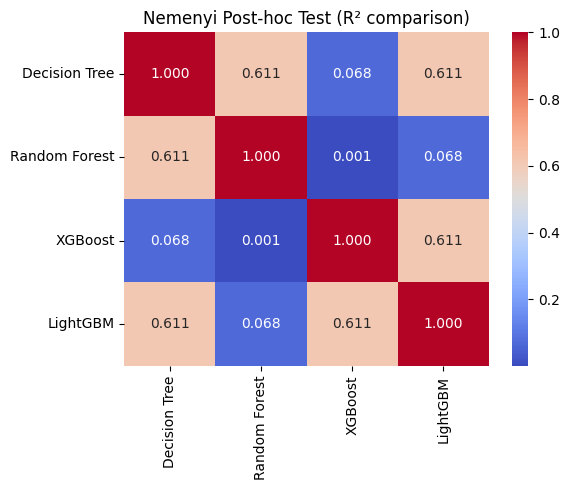


📊 Average Model Ranks (Lower = Better)
Decision Tree: 2.00
Random Forest: 1.00
XGBoost: 4.00
LightGBM: 3.00


In [ ]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import friedmanchisquare
import scikit_posthocs as sp

# =========================
# 1. K-Fold Setup
# =========================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# =========================
# 2. IMPORTANT FIX: create dictionary
# =========================
model_scores = {}

# =========================
# 3. Cross-validation function
# =========================
def cross_validate_regressor(model, name):
    scores = cross_val_score(
        model,
        X_scaled,
        y_reg,
        cv=kf,
        scoring='r2',
        n_jobs=-1
    )

    # SAVE SCORES (this fixes your error)
    model_scores[name] = scores

    print(f"\n🔁 5-Fold Cross-Validation ({name})")
    print("R² Scores:", scores)
    print(f"Mean R²: {scores.mean():.4f}")
    print(f"Std Dev: {scores.std():.4f}")

    return scores

# =========================
# 4. Run models
# =========================

cross_validate_regressor(
    DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=42),
    "Decision Tree"
)

cross_validate_regressor(
    RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1),
    "Random Forest"
)

cross_validate_regressor(
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost"
)

cross_validate_regressor(
    LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM"
)

# =========================
# 5. Extract scores (NOW SAFE)
# =========================
dt_scores  = model_scores["Decision Tree"]
rf_scores  = model_scores["Random Forest"]
xgb_scores = model_scores["XGBoost"]
lgb_scores = model_scores["LightGBM"]

# =========================
# 6. Friedman Test
# =========================
stat, p = friedmanchisquare(dt_scores, rf_scores, xgb_scores, lgb_scores)

print("\n📊 Friedman Test Result")
print(f"Statistic = {stat:.4f}")
print(f"p-value   = {p:.4f}")

if p < 0.05:
    print("👉 Significant differences exist between models ✅")
else:
    print("👉 No significant differences detected ❌")

# =========================
# 7. Nemenyi Test
# =========================
scores_matrix = np.vstack([
    dt_scores,
    rf_scores,
    xgb_scores,
    lgb_scores
]).T

model_names = ["Decision Tree", "Random Forest", "XGBoost", "LightGBM"]

nemenyi = sp.posthoc_nemenyi_friedman(scores_matrix)

nemenyi.columns = model_names
nemenyi.index = model_names

print("\n📊 Nemenyi Post-hoc Test (p-values)")
print(nemenyi)

# =========================
# 8. Heatmap
# =========================
plt.figure(figsize=(6,5))
sns.heatmap(nemenyi, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Nemenyi Post-hoc Test (R² comparison)")
plt.tight_layout()
plt.show()

# =========================
# 9. Average Ranks
# =========================
ranks = np.argsort(np.argsort(-scores_matrix, axis=1), axis=1) + 1
avg_ranks = np.mean(ranks, axis=0)

print("\n📊 Average Model Ranks (Lower = Better)")
for name, rank in zip(model_names, avg_ranks):
    print(f"{name}: {rank:.2f}")

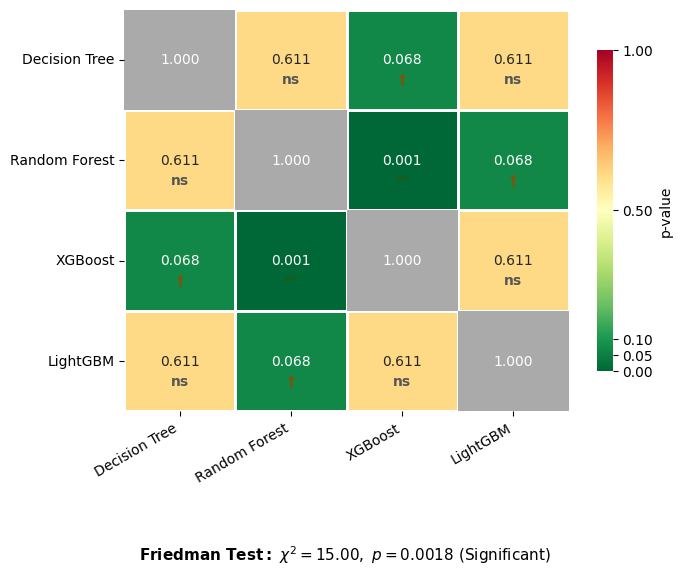

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# Your regression Nemenyi result (FROM YOUR OUTPUT)
# ============================================================
model_names = ["Decision Tree", "Random Forest", "XGBoost", "LightGBM"]

nemenyi_matrix = np.array([
    [1.000000, 0.611061, 0.068119, 0.611061],
    [0.611061, 1.000000, 0.001363, 0.068119],
    [0.068119, 0.001363, 1.000000, 0.611061],
    [0.611061, 0.068119, 0.611061, 1.000000]
])

# ============================================================
# Plot
# ============================================================
plt.figure(figsize=(7, 5.5))

ax = sns.heatmap(
    nemenyi_matrix,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn_r",   # green = significant (low p), red = not significant
    vmin=0,
    vmax=1,
    xticklabels=model_names,
    yticklabels=model_names,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "p-value",
        "shrink": 0.8,
        "ticks": [0, 0.05, 0.10, 0.5, 1.0]
    }
)

# ============================================================
# Significance overlay (your paper-style markers)
# ============================================================
n = len(model_names)

for i in range(n):
    for j in range(n):
        p = nemenyi_matrix[i, j]

        if i == j:
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                fill=True,
                color="#AAAAAA",
                lw=0
            ))
            ax.text(j + 0.5, i + 0.5, " ",
                    ha="center", va="center",
                    fontsize=12, color="white", fontweight="bold")
        else:
            if p < 0.001:
                marker = "***"
                color = "#1A5C1A"
            elif p < 0.01:
                marker = "**"
                color = "#1A5C1A"
            elif p < 0.05:
                marker = "*"
                color = "#1A5C1A"
            elif p < 0.10:
                marker = "†"
                color = "#854F0B"
            else:
                marker = "ns"
                color = "#555555"

            ax.text(j + 0.5, i + 0.70,
                    marker,
                    ha="center",
                    va="center",
                    fontsize=10,
                    fontweight="bold",
                    color=color)

# ============================================================
# Formatting
# ============================================================

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
# ============================================================
# Friedman Test Result (below heatmap)
# ============================================================
plt.figtext(
    0.5, -0.03,
    r'$\bf{Friedman\ Test:}$ '
    r'$\chi^2 = 15.00,\ p = 0.0018$ (Significant)',
    ha='center',
    fontsize=11
)

# Leave space for the text
plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.show()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Step 1 — define reference values (replace with your actual values)
ref = {
    'SO2': 20,
    'NO2': 40,
    'NOX': 100,
    'CO': 10,
    'O3': 50
}

# Step 2 — reconstruct HI safely
df['HI_reconstructed'] = (
    df['SO2']/ref['SO2'] +
    df['NO2']/ref['NO2'] +
    df['NOX']/ref['NOX'] +
    df['CO']/ref['CO'] +
    df['O3']/ref['O3']
)

# Step 3 — correlation (handle missing values safely)
valid = df[['HI', 'HI_reconstructed']].dropna()

correlation = np.corrcoef(valid['HI'], valid['HI_reconstructed'])[0, 1]

print(f"HI vs HI_reconstructed correlation: {correlation:.6f}")

HI vs HI_reconstructed correlation: 0.903522


In [ ]:
from sklearn.model_selection import KFold
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold_idx, (train_idx, test_idx) in enumerate(kf.split(X)):

    X_fold = X.iloc[test_idx]
    y_fold = y.iloc[test_idx]

    print(f"\nFold {fold_idx+1}:")

    # Only print PM2.5 if it exists in X
    if "PM2.5" in X_fold.columns:
        print(f"  PM2.5 mean: {X_fold['PM2.5'].mean():.2f}")

    print(f"  HI mean:    {y_fold.mean():.4f}")
    print(f"  HI std:     {y_fold.std():.4f}")
    print(f"  HI min/max: {y_fold.min():.4f} / {y_fold.max():.4f}")


Fold 1:
  HI mean:    0.5302
  HI std:     0.8234
  HI min/max: 0.0000 / 2.0000

Fold 2:
  HI mean:    0.5433
  HI std:     0.8316
  HI min/max: 0.0000 / 2.0000

Fold 3:
  HI mean:    0.5329
  HI std:     0.8270
  HI min/max: 0.0000 / 2.0000

Fold 4:
  HI mean:    0.5364
  HI std:     0.8304
  HI min/max: 0.0000 / 2.0000

Fold 5:
  HI mean:    0.5381
  HI std:     0.8297
  HI min/max: 0.0000 / 2.0000


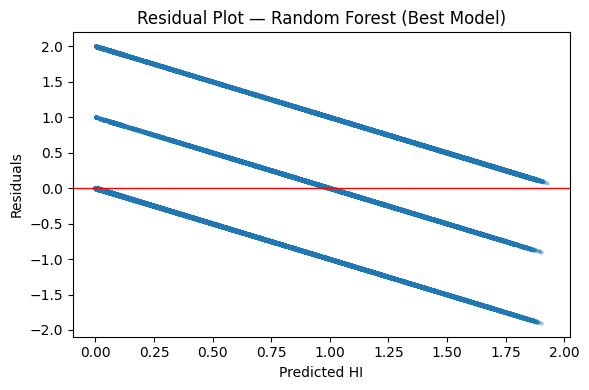

Mean residual: 0.014236061188549733
Std residual: 0.5680337806891649


In [ ]:
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# =========================
# 🏆 Best Model (Random Forest)
# =========================
best_regressor = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# =========================
# 🔁 Out-of-fold predictions
# =========================
y_pred_oof = cross_val_predict(best_regressor, X, y, cv=5, n_jobs=-1)
residuals = y - y_pred_oof

# =========================
# 📊 Residual Plot
# =========================
plt.figure(figsize=(6,4))
plt.scatter(y_pred_oof, residuals, alpha=0.3, s=5)

plt.axhline(0, color='red', linewidth=1)

plt.xlabel('Predicted HI')
plt.ylabel('Residuals')
plt.title('Residual Plot — Random Forest (Best Model)')

plt.tight_layout()
plt.savefig('residuals_rf_best.png', dpi=300)
plt.show()

# =========================
# 📌 Extra diagnostics
# =========================
print("Mean residual:", np.mean(residuals))
print("Std residual:", np.std(residuals))

In [ ]:
model.fit(X_train, y_train)

r2_train = model.score(X_train, y_train)
r2_test  = model.score(X_test, y_test)
gap      = r2_train - r2_test

print(f"Train R²: {r2_train:.4f}")
print(f"Test  R²: {r2_test:.4f}")
print(f"Gap:      {gap:.4f}")

Train R²: 0.8982
Test  R²: 0.8699
Gap:      0.0283


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# For Random Forest or CatBoost regressor
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

PM10            0.505415
CO              0.063341
NOX             0.063233
RH              0.045260
Temperature     0.041783
BP              0.039252
SO2             0.030544
V Wind Speed    0.027376
CO 8hr          0.026640
NO2             0.024286
O3 8hr          0.021079
Rain            0.019692
O3              0.019625
NO              0.019336
Wind Dir        0.019096
Wind Speed      0.017079
Solar Rad       0.016963
dtype: float32


In [ ]:
from sklearn.model_selection import KFold
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold_idx, (train_idx, test_idx) in enumerate(kf.split(X)):

    X_fold = X.iloc[test_idx]
    y_fold = y.iloc[test_idx]

    print(f"\nFold {fold_idx+1}:")

    # Only run if column exists
    if "PM2.5" in X_fold.columns:
        print(f"  PM2.5 mean: {X_fold['PM2.5'].mean():.2f}")

    print(f"  HI mean:    {y_fold.mean():.4f}")
    print(f"  HI std:     {y_fold.std():.4f}")
    print(f"  HI min/max: {y_fold.min():.4f} / {y_fold.max():.4f}")


Fold 1:
  HI mean:    0.5302
  HI std:     0.8234
  HI min/max: 0.0000 / 2.0000

Fold 2:
  HI mean:    0.5433
  HI std:     0.8316
  HI min/max: 0.0000 / 2.0000

Fold 3:
  HI mean:    0.5329
  HI std:     0.8270
  HI min/max: 0.0000 / 2.0000

Fold 4:
  HI mean:    0.5364
  HI std:     0.8304
  HI min/max: 0.0000 / 2.0000

Fold 5:
  HI mean:    0.5381
  HI std:     0.8297
  HI min/max: 0.0000 / 2.0000
